<a href="https://colab.research.google.com/github/virajrank48-max/Financial_Analytics/blob/main/NBFC_Credit_Risk/NBFC_Credit_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Analytics of Bajaj Finance and Mahindra Finance


**Inputs:** `NBFC_merged_final.xlsx` (sheets `Panel`, `Segments`, `Fill_Log`, `Change_Log`) in the notebook folder or `data/`. Optional: `Consolidated_Segment_Data_Clean.xlsx` for a cross-check in Part E.

**Project:** Group project, Financial Analytics, Symbiosis School of Economics, Pune. Notebook and analysis by Viraj Rank. See `README.md` for results, data notes and limitations, and `presentation/` for the 7 Cs deck.

## Part 0. Setup and configuration

**Requirements:** Python 3.9+, `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `openpyxl`. Place `NBFC_merged_final.xlsx` (and optionally `Consolidated_Segment_Data_Clean.xlsx`) in the same folder as this notebook, then run all cells. Charts are saved to `./figures` and results to `./outputs`.

In [ ]:
import os, itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)

# ---------------- configuration (edit here) ----------------
PANEL_FILE = "NBFC_merged_final.xlsx"
SEG_CLEAN_FILE = "Consolidated_Segment_Data_Clean.xlsx"   # optional cross-check
CRAR_MIN, TIER1_MIN = 15, 10       # RBI minimum capital ratios (%)
PCR_BASELINE = 60                  # conservative provision-coverage baseline (%)
MC_DRAWS, SEED = 10000, 42         # Monte Carlo settings for Part G
# ------------------------------------------------------------

NAVY, SLATE, EM, AMB, RED, PURPLE = "#0A2540", "#4A5568", "#059669", "#D97706", "#DC2626", "#7C3AED"
COL = {"Bajaj Finance": NAVY, "Mahindra Finance": AMB}
SHORT = {"Bajaj Finance": "Bajaj", "Mahindra Finance": "Mahindra"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.titlecolor": NAVY, "legend.frameon": False, "font.size": 9})
os.makedirs("figures", exist_ok=True); os.makedirs("outputs", exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", bbox_inches="tight"); plt.show()

def find(fname):
    for d in [".", "data", "/mnt/user-data/uploads", os.path.expanduser("~/Downloads")]:
        p = os.path.join(d, fname)
        if os.path.exists(p): return p
    raise FileNotFoundError(f"{fname} not found. Put it next to this notebook.")

def lakh(v, _=None):
    return f"{v/1e5:.1f}L" if abs(v) >= 1e5 else f"{v/1e3:.0f}k"
print("Setup complete")

Setup complete


## Part 1. Data loading and audit

The `Panel` sheet has one row per company-year. `Segments` has one row per segment-year. `Fill_Log` and `Change_Log` document what the compiler estimated or changed, so we read them first and carry the warnings through the analysis.

In [ ]:
P_RAW = pd.read_excel(find(PANEL_FILE), sheet_name="Panel")
SEG   = pd.read_excel(find(PANEL_FILE), sheet_name="Segments")
FILL  = pd.read_excel(find(PANEL_FILE), sheet_name="Fill_Log")
CHG   = pd.read_excel(find(PANEL_FILE), sheet_name="Change_Log")

yshort = lambda s: "FY" + s[-2:]
P_RAW["y"] = P_RAW["FY"].map(yshort); SEG["y"] = SEG["FY"].map(yshort)
YEARS = [yshort(f) for f in sorted(P_RAW["FY"].unique())]
COS = ["Bajaj Finance", "Mahindra Finance"]

print("Panel:", P_RAW.shape, "| Segments:", SEG.shape, "| Fill_Log:", FILL.shape)
print("Basis values:", P_RAW["Basis"].unique().tolist(), "| Years:", YEARS[0], "to", YEARS[-1])
assert set(P_RAW["Basis"]) == {"Consolidated"}, "Panel contains non-consolidated rows"
assert P_RAW.groupby("Company").size().eq(10).all(), "Each company must have 10 years"

Panel: (20, 64) | Segments: (154, 16) | Fill_Log: (73, 5)
Basis values: ['Consolidated'] | Years: FY17 to FY26


In [ ]:
# 1a. Missing values in the panel (only columns with gaps)
miss = P_RAW.groupby("Company").apply(lambda g: g.isna().sum()).T
miss = miss[(miss > 0).any(axis=1)]
display(miss if len(miss) else "No missing values in Panel")

# 1b. Estimated / filled values (from Fill_Log)
est_tab = FILL.groupby(["Column", "Company"]).size().unstack(fill_value=0)
est_tab["Total"] = est_tab.sum(axis=1)
display(est_tab.sort_values("Total", ascending=False))

EST = {(r.Company, r.y): {x.strip() for x in r.Estimated_Fields.split(",")} if isinstance(r.Estimated_Fields, str) else set()
       for r in P_RAW.itertuples()}
def is_est(co, y, *fields):
    return any(f in EST[(co, y)] for f in fields)

Company,Bajaj Finance,Mahindra Finance
AUM_growth_pct,1,1
Net_Worth_incl_NCI,10,0
Estimated_Fields,1,0
CoF_pct_reported,0,1


Company,Bajaj Finance,Mahindra Finance,Total
Column,,,
OneTime_Prov,7,10,17
Net_Worth,8,0,8
Total_Assets,8,0,8
Borrowings,8,0,8
Writeoffs,6,0,6
ECL_S2,1,1,2
ECL_S1,1,1,2
Deposits,2,0,2
AUM_avg,1,1,2


In [ ]:
# 1c. Internal consistency checks
chk = []
d = P_RAW.copy()
chk.append(("Net NPA <= Gross NPA (all rows)", bool((d.Net_NPA <= d.Gross_NPA + 1e-6).all())))
chk.append(("CRAR >= Tier 1 (all rows)", bool((d.CRAR >= d.Tier1).all())))
chk.append(("Opex/NTI recomputes within 0.1 pp", bool((d.Opex / d.NTI * 100 - d.Opex_to_NTI_pct).abs().max() < 0.1)))
chk.append(("GNPA% calc vs reported within 0.25 pp", bool((d.GNPA_pct_calc - d.GNPA_pct_reported).abs().max() < 0.25)))
chk.append(("Segment shares sum to 100 per company-year", bool(SEG.groupby(["Company", "y"]).Share_pct.sum().sub(100).abs().max() < 0.5)))
display(pd.DataFrame(chk, columns=["Check", "Passed"]))

print("\nKnown caveats recorded by the data compiler (Change_Log):")
for t in CHG.iloc[:, 0].dropna().tolist():
    if t.startswith(("Estimated", "Mahindra *", "Bajaj FY", "Mahindra has", "Segment-derived", "Mahindra Debt")): print(" -", t)

,Check,Passed
0,Net NPA <= Gross NPA (all rows),True
1,CRAR >= Tier 1 (all rows),True
2,Opex/NTI recomputes within 0.1 pp,True
3,GNPA% calc vs reported within 0.25 pp,True
4,Segment shares sum to 100 per company-year,True



Known caveats recorded by the data compiler (Change_Log):
 - Estimated values (Bajaj Total_Assets/Net_Worth/Borrowings/Deposits/Writeoffs, FY17 stage data, OneTime_Prov zeros) are KEPT but flagged in Estimated_Fields; see Fill_Log for method.
 - Mahindra *_reported ratios are the source file's own calculated ratios (Mahindra does not print consolidated %).
 - Bajaj FY2017-18 segment AUM (84,033) does not equal AUM (82,422) - source-side difference, not fixed.
 - Mahindra has no segment rows for FY2016-17 (source has none).
 - Segment-derived Panel columns (HighRisk_Share_pct, Unsecured_Share_pct) depend on analyst risk labels and allocated GNPA; Mahindra FY2016-17 values are nearest-year fill. Mahindra Unsecured share counts "Mixed" segments at 50%.
 - Mahindra Debt_to_Equity_x now uses owners equity, so differs from the Mahindra source master by <=1.5%.


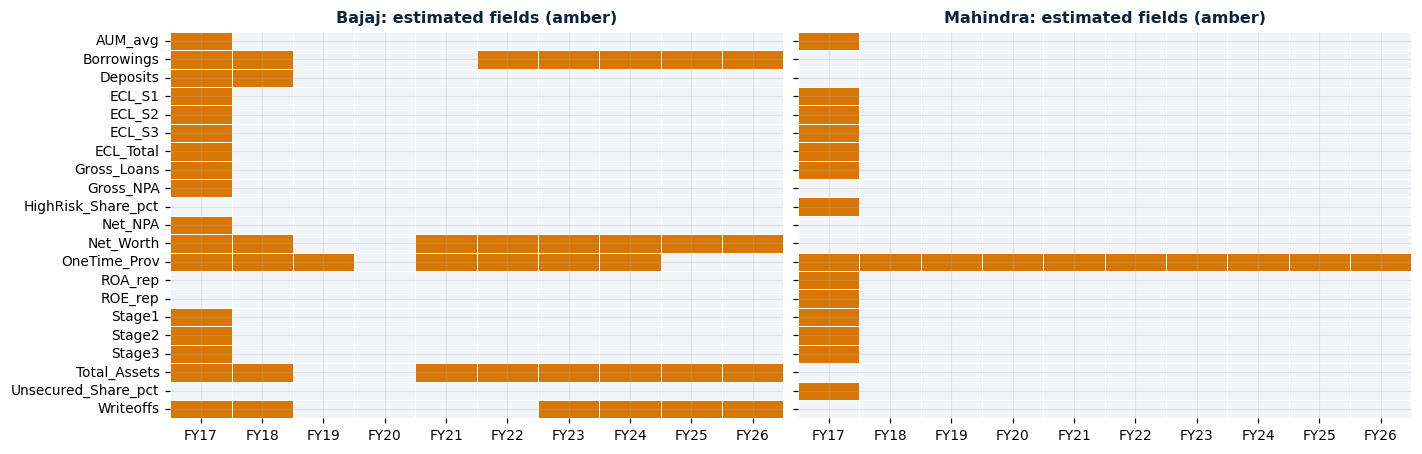

In [ ]:
# 1d. Heatmap of estimated cells: which fields are estimated, by company-year
fields = sorted({f for s in EST.values() for f in s})
H = pd.DataFrame({(co, y): {f: int(f in EST[(co, y)]) for f in fields} for co in COS for y in YEARS}).T
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for a, co in zip(ax, COS):
    sns.heatmap(H.loc[co].T, cmap=["#F1F5F9", AMB], cbar=False, linewidths=.5, linecolor="white", ax=a)
    a.set_title(f"{SHORT[co]}: estimated fields (amber)")
savefig("01_estimated_fields")

## Part 2. Analysis variables

We map the long panel column names to short analysis names. Reported ratios are used where available (for example reported GNPA, NNPA, PCR and cost of funds), and `PPOP = NTI - Opex` uses the panel's own figures. Year-end cost of funds in the panel understates the true cost, so we use the reported series, as the Change_Log advises.

In [ ]:
A = pd.DataFrame({
    "co": P_RAW.Company, "y": P_RAW.y,
    "aum": P_RAW.AUM, "g": P_RAW.AUM_growth_pct,
    "gnpa": P_RAW.GNPA_pct_reported, "nnpa": P_RAW.NNPA_pct_reported, "pcr": P_RAW.PCR_pct_reported,
    "s2": P_RAW.Stage2_pct, "cc": P_RAW.CreditCost_pct, "llnti": P_RAW.LossProv_to_NTI_pct,
    "nti": P_RAW.NTI, "opex": P_RAW.Opex, "ppop": P_RAW.NTI - P_RAW.Opex, "pat": P_RAW.PAT,
    "roa": P_RAW.ROA_pct, "roe": P_RAW.ROE_pct, "cir": P_RAW.Opex_to_NTI_pct, "cof": P_RAW.CoF_pct_reported,
    "crar": P_RAW.CRAR, "t1": P_RAW.Tier1, "lev": P_RAW.Leverage_rep, "de": P_RAW.Debt_to_Equity_x,
    "hr": P_RAW.HighRisk_Share_pct, "uns": P_RAW.Unsecured_Share_pct,
    "ind": P_RAW.IndAS, "covid": P_RAW.Covid_year})
A["cagr3"] = A.groupby("co").aum.transform(lambda s: ((s / s.shift(3)) ** (1 / 3) - 1) * 100)
A["cap"] = A.crar - CRAR_MIN           # CRAR headroom over the RBI floor (pp)
def C(co): return A[A.co == co].set_index("y").loc[YEARS]

LABEL = {"g": "AUM growth", "gnpa": "Gross NPA", "nnpa": "Net NPA", "pcr": "PCR", "s2": "Stage 2", "cc": "Credit cost",
         "llnti": "Loss/NTI", "roa": "RoA", "roe": "RoE", "cir": "Cost/income", "cof": "Cost of funds",
         "crar": "CRAR", "t1": "Tier 1", "lev": "Leverage", "de": "Debt/equity", "cap": "CRAR headroom"}
display(A[A.y.isin(["FY17", "FY21", "FY26"])].set_index(["co", "y"])[["aum", "gnpa", "nnpa", "pcr", "s2", "cc", "roa", "roe", "cir", "crar"]].round(2))

aum  gnpa  nnpa    pcr     s2    cc   roa    roe    cir   crar
co               y                                                                         
Bajaj Finance    FY17   60196.00  1.68  0.44  74.00   1.34  1.54  3.70  21.60  41.45  20.30
                 FY21  152947.00  1.79  0.75  58.00   4.45  3.98  3.07  12.77  30.74  28.31
                 FY26  509975.00  1.01  0.41  60.00   0.94  2.22  4.30  18.10  32.84  21.55
Mahindra Finance FY17   47994.47  8.33  4.22  51.53  10.77  3.16  0.96   7.25  44.52  17.20
                 FY21   72239.57  9.39  4.61  53.41  14.12  5.38  0.93   5.57  32.03  26.00
                 FY26  143405.14  3.34  1.40  58.92   4.71  1.83  1.89  11.85  47.57  18.80

### Reusable company profile
The same function produces the same set of charts for each company, so Parts A and B are directly comparable.

In [ ]:
def seg_mix(co, by="Segment_Group"):
    t = SEG[SEG.Company == co].pivot_table(index="y", columns=by, values="Segment_AUM", aggfunc="sum").fillna(0)
    t = t.reindex([y for y in YEARS if y in t.index])
    return t.div(t.sum(axis=1), axis=0) * 100

def narrative(co):
    d = C(co); f = d.loc["FY26"]
    L = [f"- **Scale:** AUM rose from ₹{d.aum['FY17']:,.0f} Cr (FY17) to ₹{f.aum:,.0f} Cr (FY26), a {((f.aum/d.aum['FY17'])**(1/9)-1)*100:.1f}% nine-year CAGR; three-year CAGR to FY26 is {f.cagr3:.1f}%.",
         f"- **Asset quality:** gross NPA peaked at {d.gnpa.max():.2f}% ({d.gnpa.idxmax()}) and is {f.gnpa:.2f}% in FY26; net NPA {f.nnpa:.2f}%; PCR {f.pcr:.1f}%; Stage 2 {f.s2:.2f}%.",
         f"- **Credit cost:** peaked at {d.cc.max():.2f}% ({d.cc.idxmax()}); FY26 is {f.cc:.2f}%.",
         f"- **Profitability:** RoA {f.roa:.2f}%, RoE {f.roe:.2f}%, cost-to-income {f.cir:.1f}% (FY18: {d.cir['FY18']:.1f}%).",
         f"- **Capital:** CRAR {f.crar:.2f}% ({f.cap:+.2f} pp over the {CRAR_MIN}% floor); Tier 1 {f.t1:.2f}% ({f.t1-TIER1_MIN:+.2f} pp over {TIER1_MIN}%)."]
    display(Markdown("\n".join(L)))

def profile(co):
    d = C(co); c = COL[co]; s = SHORT[co]
    # ---- A1 scale and growth
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    ax[0].bar(YEARS, d.aum, color=c); ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lakh)); ax[0].set_title(f"{s}: AUM (₹ Cr; L = lakh)")
    ax[1].bar(YEARS, d.g, color=[EM if v >= 0 else RED for v in d.g.fillna(0)]); ax[1].axhline(0, color=SLATE, lw=.8); ax[1].set_title(f"{s}: YoY AUM growth (%)")
    ax[2].bar(YEARS, d.ppop, color=c, alpha=.35, label="PPOP"); ax[2].bar(YEARS, d.pat, color=c, label="PAT")
    ax[2].yaxis.set_major_formatter(mtick.FuncFormatter(lakh)); ax[2].set_title(f"{s}: PPOP and PAT (₹ Cr)"); ax[2].legend()
    for a in ax: a.tick_params(axis="x", rotation=45)
    savefig(f"{s}_A1_scale")
    # ---- A2 asset quality
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    for v, ls in [("gnpa", "-"), ("nnpa", "--"), ("s2", ":")]:
        ax[0].plot(YEARS, d[v], ls, marker="o", color=c, label=LABEL[v])
    ax[0].set_title(f"{s}: gross NPA, net NPA, Stage 2 (% of loans)"); ax[0].legend()
    ax[1].bar(YEARS, d.pcr, color=c); ax[1].axhline(PCR_BASELINE, color=EM, ls="--", label=f"{PCR_BASELINE}% baseline")
    ax[1].set_title(f"{s}: provision coverage ratio (%)"); ax[1].legend()
    ax[2].plot(YEARS, d.cc, marker="o", color=c, label="Credit cost"); ax[2].plot(YEARS, d.llnti / 10, marker="s", color=RED, ls="--", label="Loss/NTI (÷10)")
    ax[2].set_title(f"{s}: credit cost (%) and loan losses/NTI"); ax[2].legend()
    for a in ax: a.tick_params(axis="x", rotation=45)
    savefig(f"{s}_A2_asset_quality")
    # ---- A3 profitability and efficiency
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    ax[0].bar(YEARS, d.nti, color=c, alpha=.4, label="NTI"); ax[0].bar(YEARS, d.opex, color=c, label="Opex")
    ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lakh)); ax[0].set_title(f"{s}: net total income vs operating expense (₹ Cr)"); ax[0].legend()
    ax[1].plot(YEARS, d.roa, marker="o", color=c, label="RoA (%)"); a2 = ax[1].twinx(); a2.plot(YEARS, d.roe, marker="s", ls="--", color=EM, label="RoE (%)")
    a2.grid(False); ax[1].set_title(f"{s}: RoA (left) and RoE (right)")
    ax[2].plot(YEARS, d.cir, marker="o", color=c, label="Cost/income (%)"); ax[2].plot(YEARS, d.cof * 5, marker="s", ls="--", color=SLATE, label="Cost of funds (% x5)")
    ax[2].set_title(f"{s}: efficiency and funding cost"); ax[2].legend()
    for a in ax: a.tick_params(axis="x", rotation=45)
    savefig(f"{s}_A3_profitability")
    # ---- A4 capital and leverage
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    ax[0].plot(YEARS, d.crar, marker="o", color=c, label="CRAR"); ax[0].plot(YEARS, d.t1, marker="s", ls="--", color=c, label="Tier 1")
    ax[0].axhline(CRAR_MIN, color=EM, ls=":", label=f"CRAR min {CRAR_MIN}%"); ax[0].axhline(TIER1_MIN, color=RED, ls=":", label=f"Tier 1 min {TIER1_MIN}%")
    ax[0].set_title(f"{s}: capital adequacy vs RBI minimums"); ax[0].legend(fontsize=7)
    ax[1].plot(YEARS, d.lev, marker="o", color=c); ax[1].set_title(f"{s}: leverage (assets / equity, x)")
    est = [is_est(co, y, "Borrowings", "Net_Worth") for y in YEARS]
    ax[2].plot(YEARS, d.de, color=c, lw=1.5)
    for i, (y, v) in enumerate(d.de.items()):
        ax[2].scatter(i, v, s=36, facecolors="white" if est[i] else c, edgecolors=c, zorder=3)
    ax[2].set_title(f"{s}: debt/equity (x); hollow = estimated inputs")
    for a in ax: a.tick_params(axis="x", rotation=45)
    savefig(f"{s}_A4_capital")

def profile_segments(co):
    s = SHORT[co]
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    g = seg_mix(co, "Segment_Group"); g.plot(kind="bar", stacked=True, ax=ax[0], colormap="tab20", width=.8)
    ax[0].set_title(f"{s}: portfolio mix by harmonised segment group (% of segment AUM)"); ax[0].legend(fontsize=7, bbox_to_anchor=(1, 1)); ax[0].set_xlabel("")
    d = C(co).loc[[y for y in YEARS if y in g.index]]
    ax[1].plot(d.index, d.hr, marker="o", color=COL[co], label="High-risk share (%)")
    ax[1].plot(d.index, d.uns, marker="s", ls="--", color=SLATE, label="Unsecured share (%)"); ax[1].legend()
    ax[1].set_title(f"{s}: high-risk and unsecured share of book")
    if co == "Bajaj Finance":
        for yy, t in [("FY19", "taxonomy A"), ("FY23", "B"), ("FY25", "C")]:
            ax[1].axvline(list(d.index).index(yy) - .5, color=RED, ls=":", lw=1); ax[1].text(list(d.index).index(yy) - .45, ax[1].get_ylim()[1] * .97, t, color=RED, fontsize=7, va="top")
        ax[1].set_xlabel("Red dotted lines: Bajaj segment taxonomy changes (FY17-18 not comparable)")
    savefig(f"{s}_A5_segments")

## Part A. Bajaj Finance (consolidated)

### A0. Headline facts (computed from the data)

- **Scale:** AUM rose from ₹60,196 Cr (FY17) to ₹509,975 Cr (FY26), a 26.8% nine-year CAGR; three-year CAGR to FY26 is 27.3%.
- **Asset quality:** gross NPA peaked at 1.79% (FY21) and is 1.01% in FY26; net NPA 0.41%; PCR 60.0%; Stage 2 0.94%.
- **Credit cost:** peaked at 3.98% (FY21); FY26 is 2.22%.
- **Profitability:** RoA 4.30%, RoE 18.10%, cost-to-income 32.8% (FY18: 40.2%).
- **Capital:** CRAR 21.55% (+6.55 pp over the 15% floor); Tier 1 20.67% (+10.67 pp over 10%).

### A1. Scale and growth

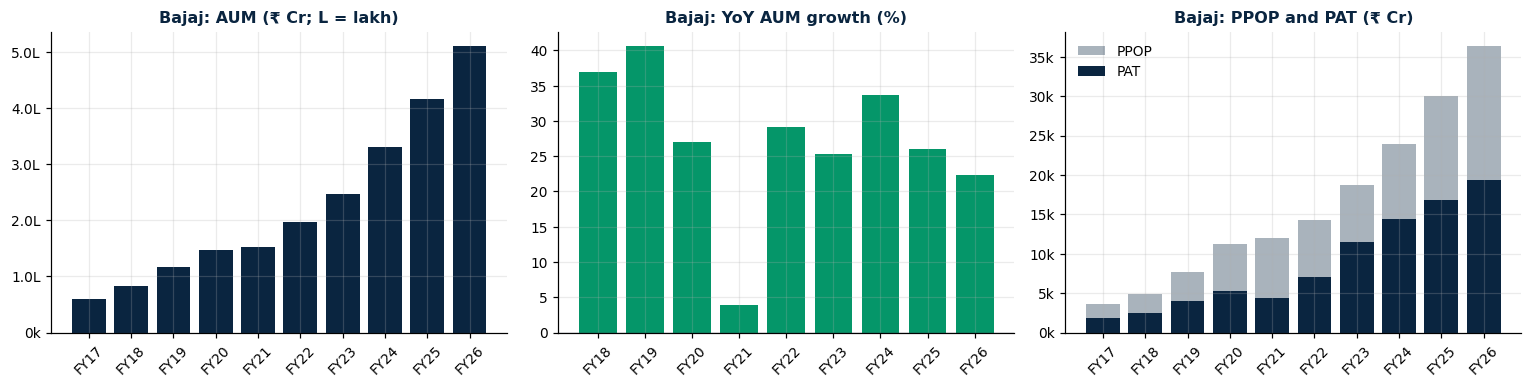

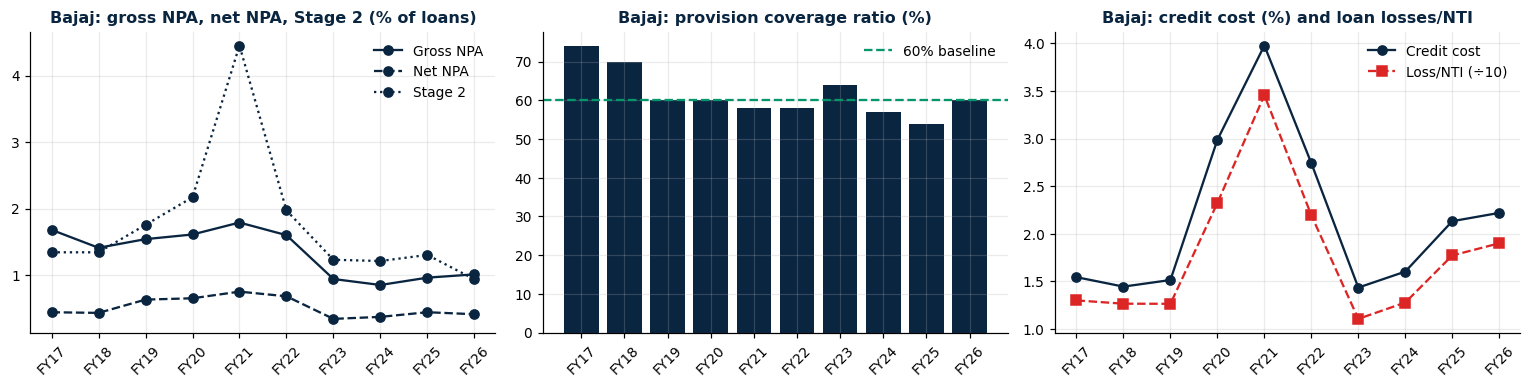

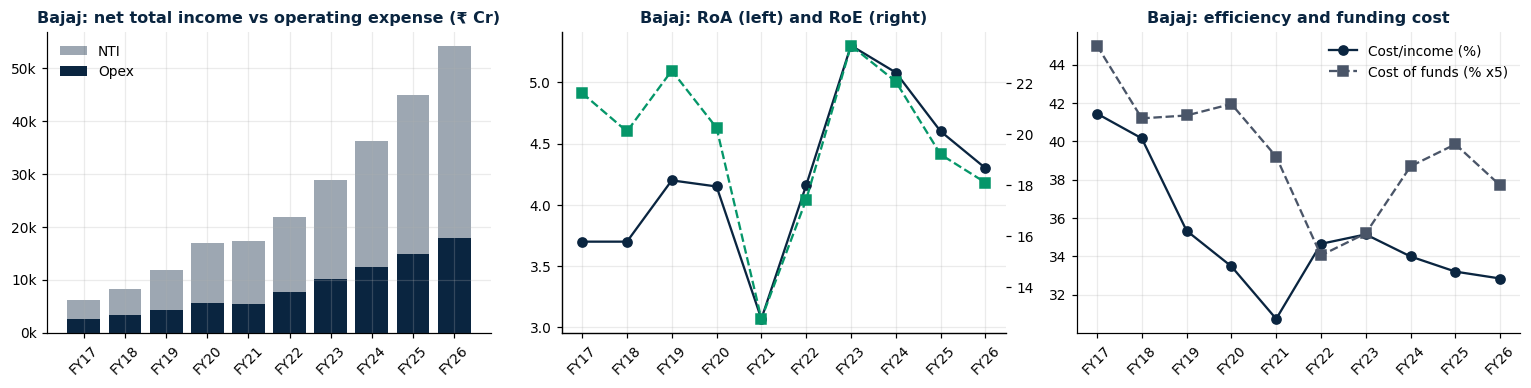

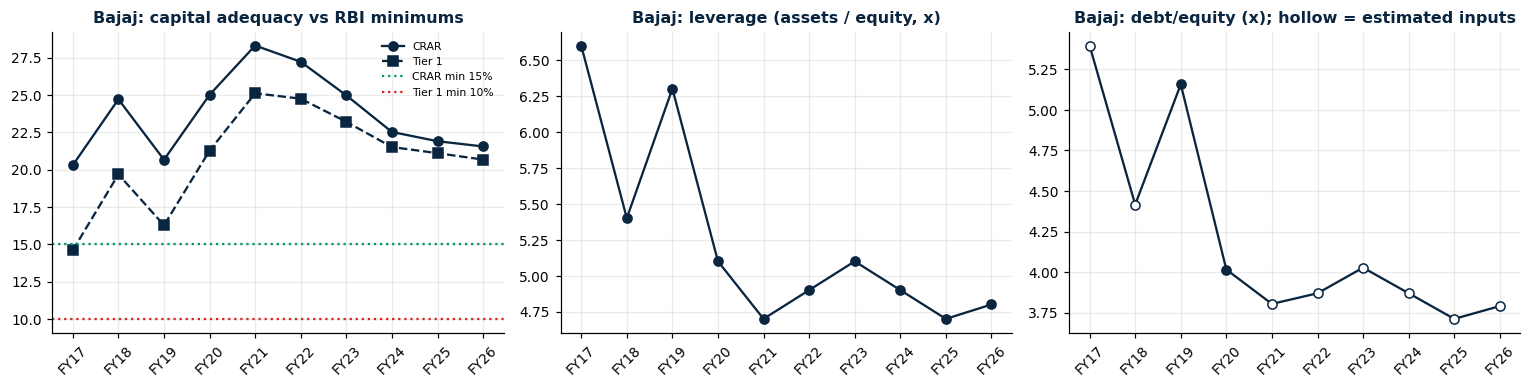

In [ ]:
display(Markdown("### A0. Headline facts (computed from the data)")); narrative("Bajaj Finance")
display(Markdown("### A1. Scale and growth"));
profile("Bajaj Finance")

### A5. Portfolio mix and risk tiers (Bajaj)

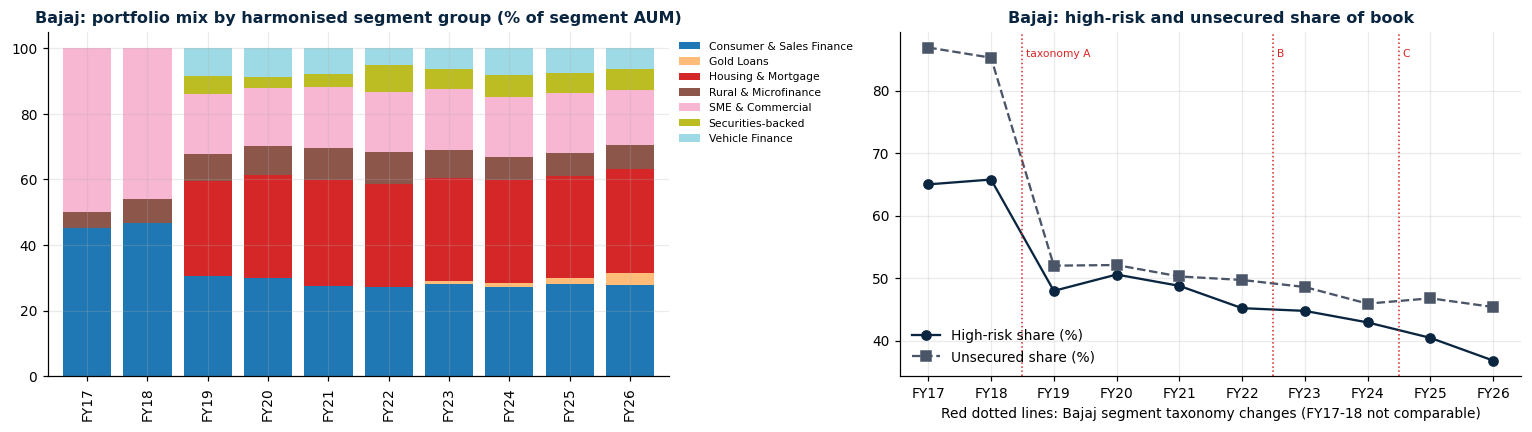

**Note:** Bajaj changed its segment taxonomy in FY19, FY23 and FY25 (5, 10, 11 and 14 segments). The group labels are the compiler's harmonised mapping, so read mix shifts at group level with caution. High-risk and unsecured shares for FY17-FY18 use the old 5-segment taxonomy and are not comparable with later years.

In [ ]:
display(Markdown("### A5. Portfolio mix and risk tiers (Bajaj)"))
profile_segments("Bajaj Finance")
display(Markdown("**Note:** Bajaj changed its segment taxonomy in FY19, FY23 and FY25 (5, 10, 11 and 14 segments). The group labels are the compiler's harmonised mapping, so read mix shifts at group level with caution. High-risk and unsecured shares for FY17-FY18 use the old 5-segment taxonomy and are not comparable with later years."))

## Part B. Mahindra Finance (consolidated)

### B0. Headline facts (computed from the data)

- **Scale:** AUM rose from ₹47,994 Cr (FY17) to ₹143,405 Cr (FY26), a 12.9% nine-year CAGR; three-year CAGR to FY26 is 16.8%.
- **Asset quality:** gross NPA peaked at 10.18% (FY18) and is 3.34% in FY26; net NPA 1.40%; PCR 58.9%; Stage 2 4.71%.
- **Credit cost:** peaked at 5.38% (FY21); FY26 is 1.83%.
- **Profitability:** RoA 1.89%, RoE 11.85%, cost-to-income 47.6% (FY18: 43.0%).
- **Capital:** CRAR 18.80% (+3.80 pp over the 15% floor); Tier 1 16.70% (+6.70 pp over 10%).

### B1-B4. Scale, asset quality, profitability, capital

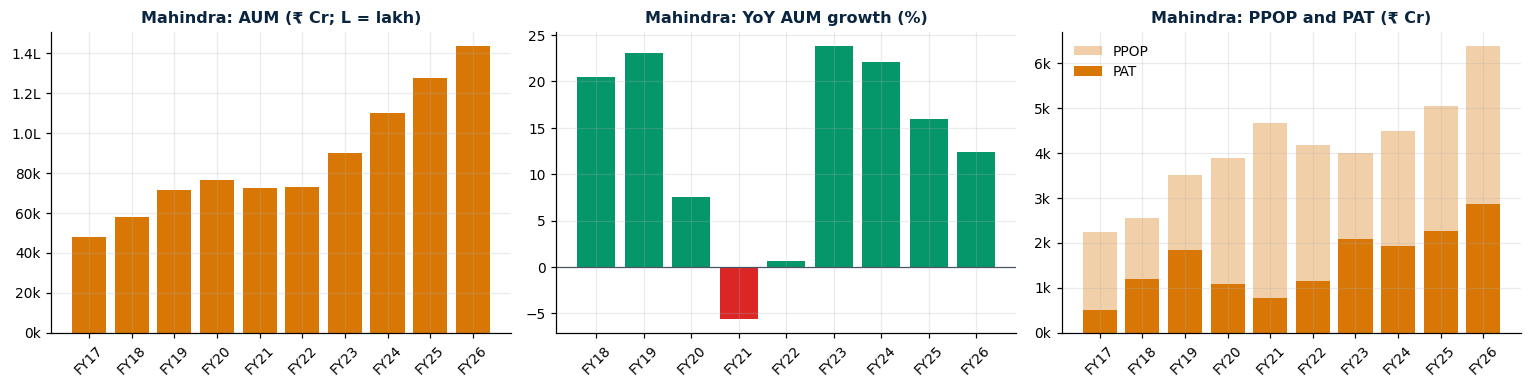

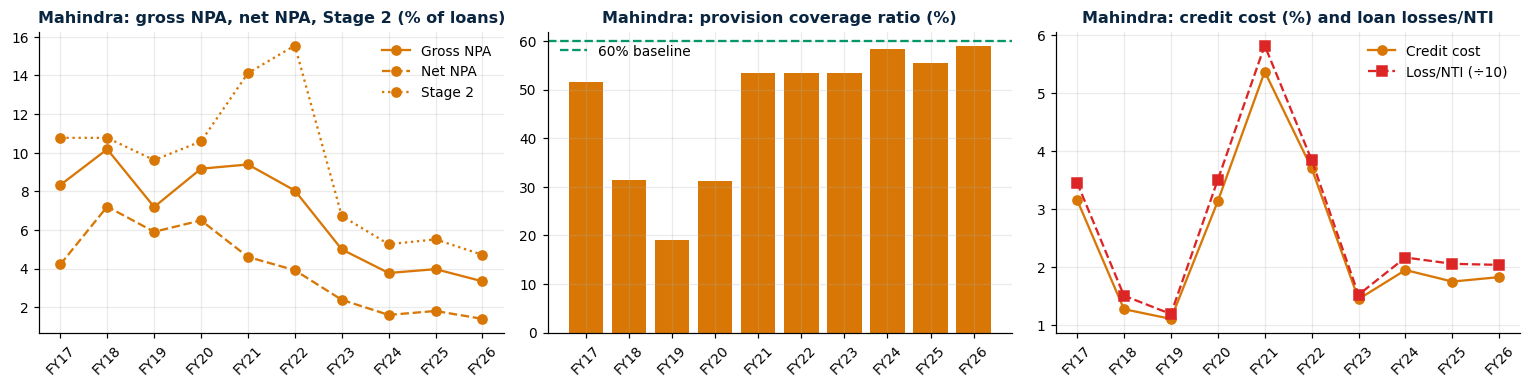

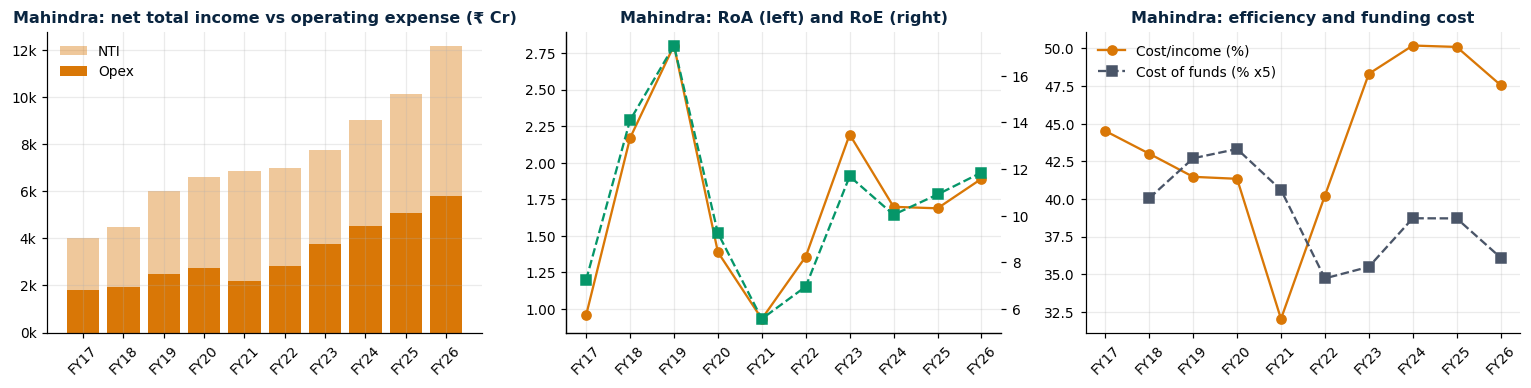

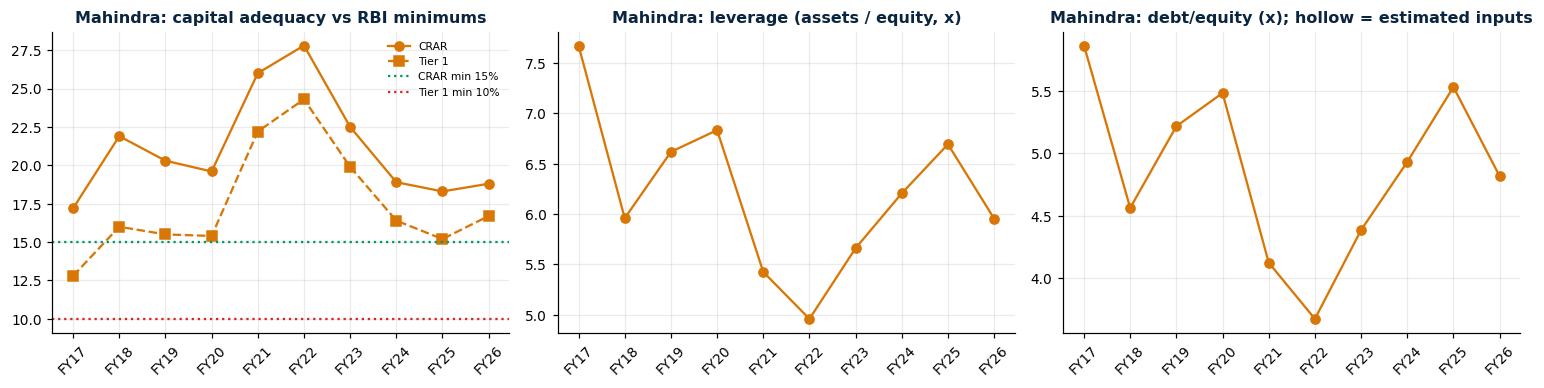

In [ ]:
display(Markdown("### B0. Headline facts (computed from the data)")); narrative("Mahindra Finance")
display(Markdown("### B1-B4. Scale, asset quality, profitability, capital"));
profile("Mahindra Finance")

### B5. Portfolio mix and risk tiers (Mahindra)

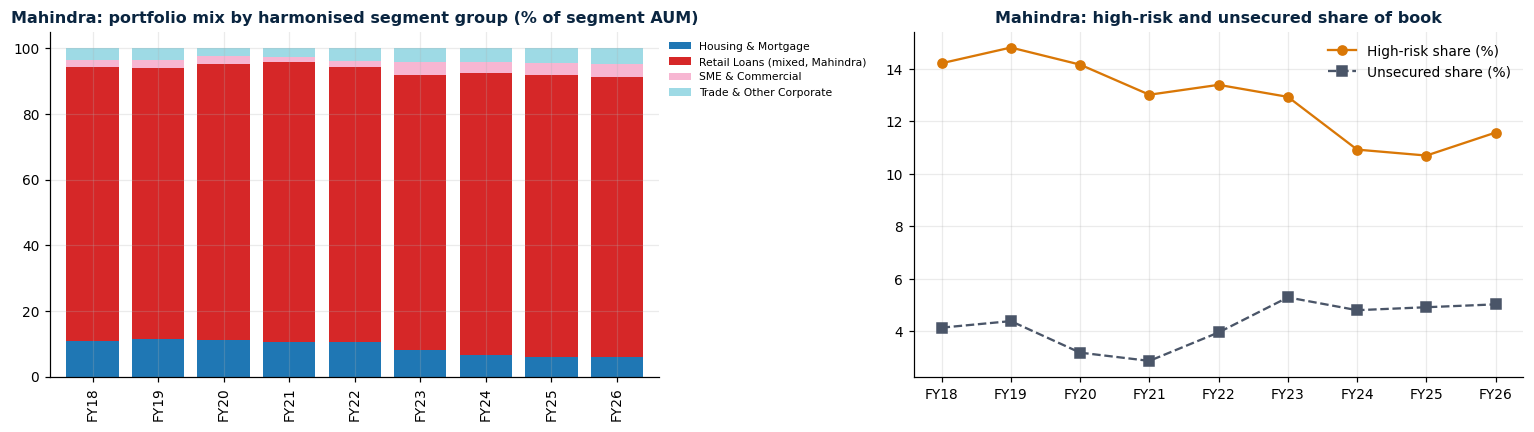

**Note:** Mahindra's product split starts in FY18 (FY17 segment shares in the panel are nearest-year fills). Its unsecured share counts 'Mixed' products (SME financing, bills of exchange) at 50%, so it is not directly comparable with Bajaj's definition.

In [ ]:
display(Markdown("### B5. Portfolio mix and risk tiers (Mahindra)"))
profile_segments("Mahindra Finance")
display(Markdown("**Note:** Mahindra's product split starts in FY18 (FY17 segment shares in the panel are nearest-year fills). Its unsecured share counts 'Mixed' products (SME financing, bills of exchange) at 50%, so it is not directly comparable with Bajaj's definition."))

## Part C. Head-to-head comparison

Same variables, both companies, one chart each. This is the bridge from company-specific facts to the cross-company index.

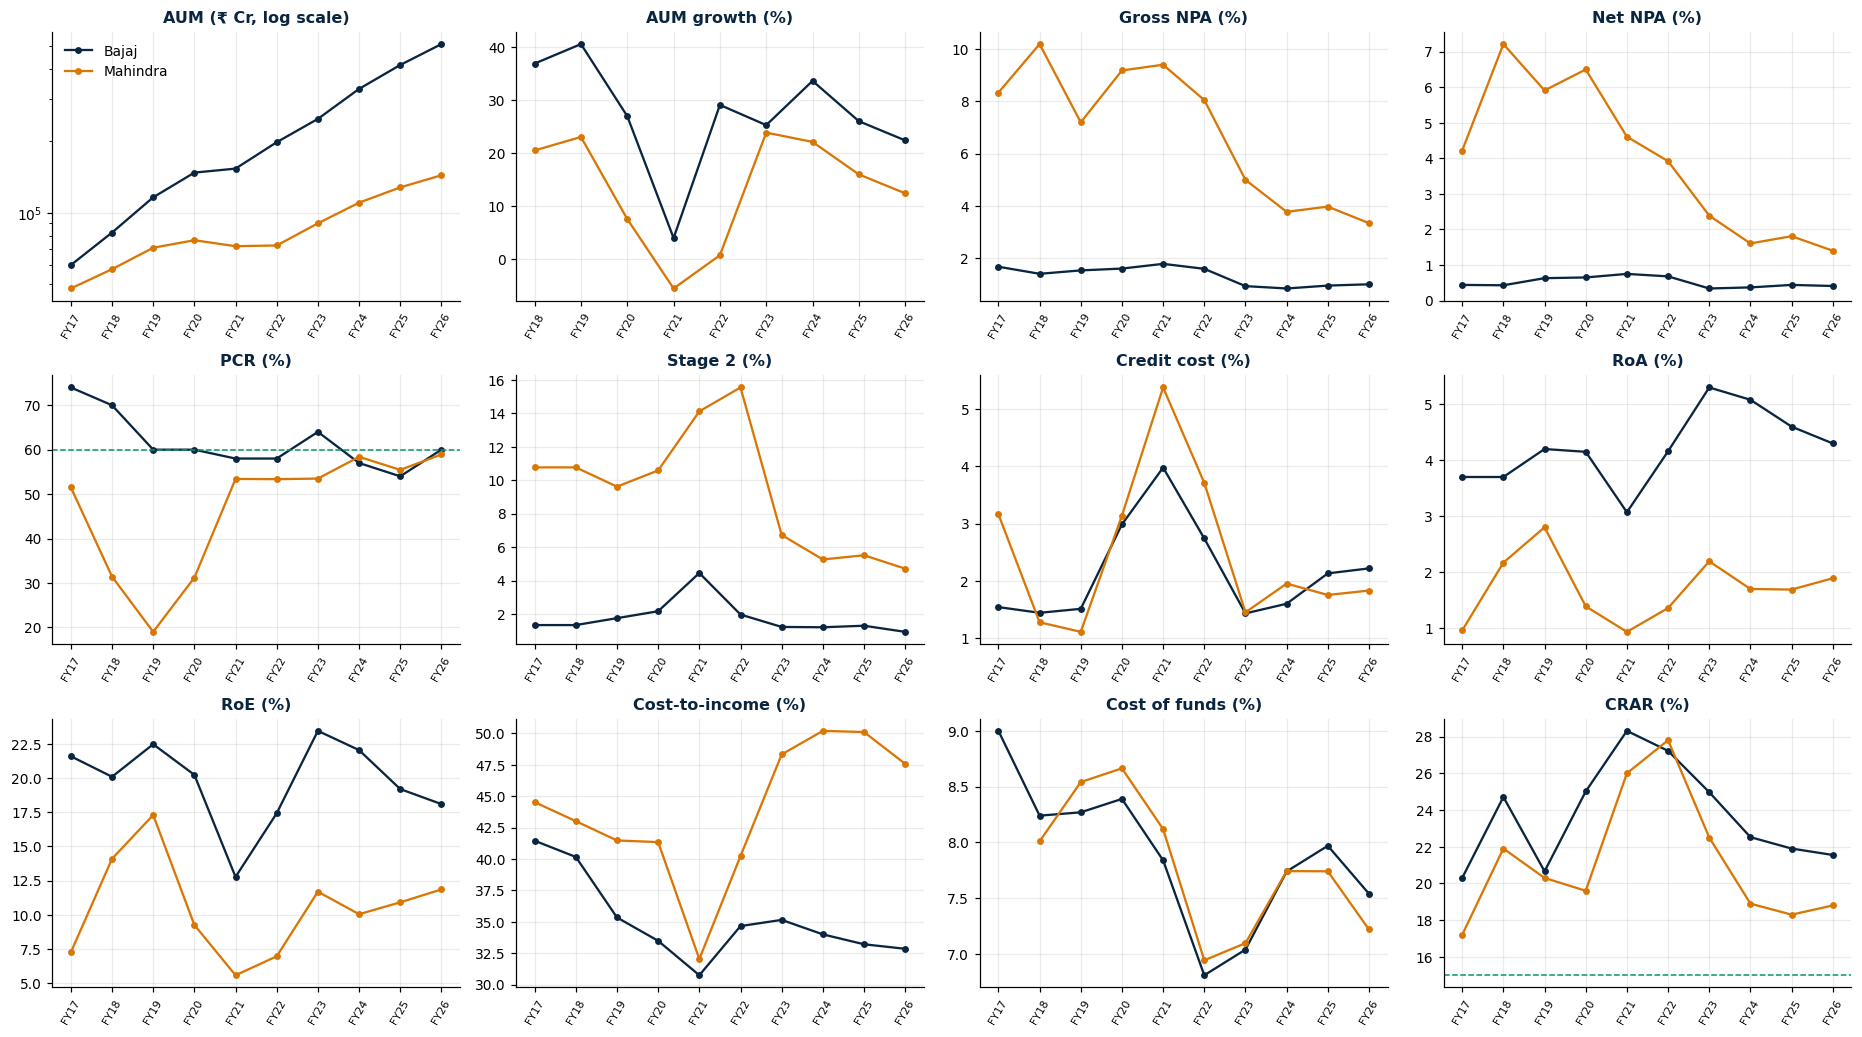

In [ ]:
PAIRS = [("aum", "AUM (₹ Cr, log scale)"), ("g", "AUM growth (%)"), ("gnpa", "Gross NPA (%)"), ("nnpa", "Net NPA (%)"),
         ("pcr", "PCR (%)"), ("s2", "Stage 2 (%)"), ("cc", "Credit cost (%)"), ("roa", "RoA (%)"),
         ("roe", "RoE (%)"), ("cir", "Cost-to-income (%)"), ("cof", "Cost of funds (%)"), ("crar", "CRAR (%)")]
fig, axes = plt.subplots(3, 4, figsize=(17, 9.5))
for ax, (v, t) in zip(axes.flat, PAIRS):
    for co in COS:
        ax.plot(YEARS, C(co)[v], marker="o", ms=3.5, color=COL[co], label=SHORT[co])
    if v == "aum": ax.set_yscale("log")
    if v == "pcr": ax.axhline(PCR_BASELINE, color=EM, ls="--", lw=1)
    if v == "crar": ax.axhline(CRAR_MIN, color=EM, ls="--", lw=1)
    ax.set_title(t); ax.tick_params(axis="x", rotation=60, labelsize=7)
axes[0, 0].legend()
savefig("C1_head_to_head")

Bajaj              Mahindra           
            FY21       FY26       FY21       FY26
aum     152947.0   509975.0   72239.57  143405.14
cagr3  22.885113  27.270774   7.696351  16.753891
gnpa        1.79       1.01     9.3911     3.3443
nnpa        0.75       0.41     4.6066     1.4013
pcr         58.0       60.0     53.408    58.9249
s2       4.45379   0.935897  14.116997   4.714157
cc      3.978007    2.21921   5.376099   1.832405
roa         3.07        4.3    0.93227   1.890086
roe        12.77       18.1   5.573615  11.852367
cir    30.737159  32.843708  32.029031  47.568741
cof         7.84       7.54     8.1196     7.2201
crar       28.31      21.55       26.0       18.8
t1         25.11      20.67       22.2       16.7
lev          4.7        4.8   5.425899   5.955407

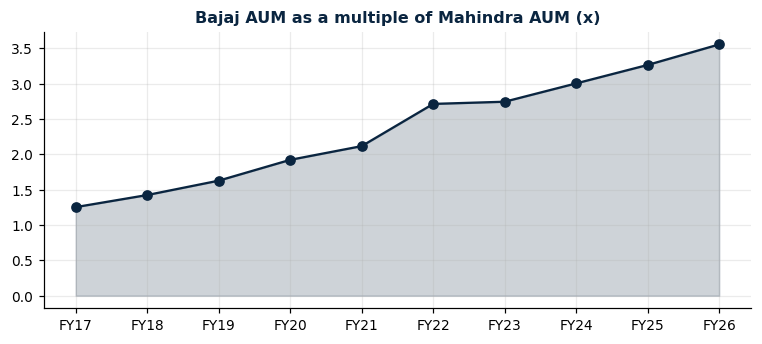

Scale multiple moved from 1.25x (FY17) to 3.56x (FY26).


In [ ]:
# C2. FY26 snapshot, FY21 (COVID peak stress) and the change between them
snap = pd.DataFrame({(SHORT[co], y): C(co).loc[y, ["aum", "cagr3", "gnpa", "nnpa", "pcr", "s2", "cc", "roa", "roe", "cir", "cof", "crar", "t1", "lev"]]
                     for co in COS for y in ["FY21", "FY26"]}).round(2)
display(snap)
ratio = (C("Bajaj Finance").aum / C("Mahindra Finance").aum)
fig, ax = plt.subplots(figsize=(7, 3.2)); ax.fill_between(YEARS, ratio, color=NAVY, alpha=.2); ax.plot(YEARS, ratio, color=NAVY, marker="o")
ax.set_title("Bajaj AUM as a multiple of Mahindra AUM (x)"); savefig("C2_scale_multiplier")
print(f"Scale multiple moved from {ratio['FY17']:.2f}x (FY17) to {ratio['FY26']:.2f}x (FY26).")

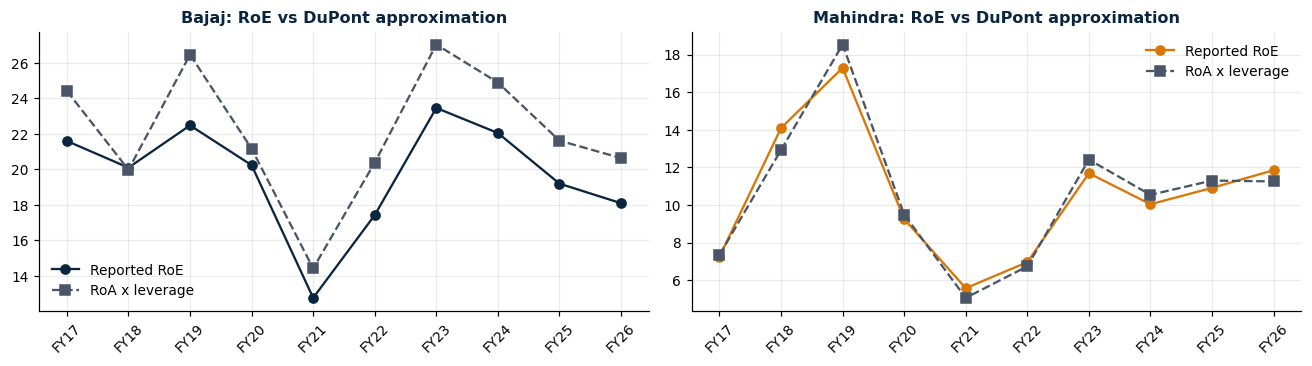

,pp of RoE (FY26)
RoA effect (at Mahindra leverage),14.4
Leverage effect (at Bajaj RoA),-5.0
DuPont approximation of the gap,9.4
Reported RoE gap (Bajaj - Mahindra),6.2
Residual (averaging / definitions),-3.1


A higher RoA drives Bajaj's RoE advantage; Mahindra's higher leverage offsets part of it. The residual likely reflects differences in averaging and definitions between reported RoE, RoA and year-end leverage (not verified in the source files).


In [ ]:
# C3. DuPont view: RoE is approximately RoA x leverage (the approximation need not match reported RoE exactly)
dp = pd.DataFrame({SHORT[co]: C(co).roa * C(co).lev for co in COS}); rep = pd.DataFrame({SHORT[co]: C(co).roe for co in COS})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for a, co in zip(ax, COS):
    a.plot(YEARS, rep[SHORT[co]], marker="o", color=COL[co], label="Reported RoE"); a.plot(YEARS, dp[SHORT[co]], marker="s", ls="--", color=SLATE, label="RoA x leverage")
    a.set_title(f"{SHORT[co]}: RoE vs DuPont approximation"); a.legend(); a.tick_params(axis="x", rotation=45)
savefig("C3_dupont")
rb, rm = C("Bajaj Finance").loc["FY26"], C("Mahindra Finance").loc["FY26"]
roa_eff = (rb.roa - rm.roa) * rm.lev; lev_eff = rb.roa * (rb.lev - rm.lev)
approx = rb.roa * rb.lev - rm.roa * rm.lev; gap = rb.roe - rm.roe
display(pd.DataFrame({"pp of RoE (FY26)": {"RoA effect (at Mahindra leverage)": roa_eff, "Leverage effect (at Bajaj RoA)": lev_eff,
    "DuPont approximation of the gap": approx, "Reported RoE gap (Bajaj - Mahindra)": gap, "Residual (averaging / definitions)": gap - approx}}).round(1))
print("A higher RoA drives Bajaj's RoE advantage; Mahindra's higher leverage offsets part of it. The residual likely reflects differences in averaging and definitions between reported RoE, RoA and year-end leverage (not verified in the source files).")

## Part D. Correlation analysis

**Design.** Within-company Pearson correlations of the main credit-risk variables across the Ind AS years (FY18 to FY26, n = 9). Four safeguards because the series are short and share trends:

1. repeat without FY21 (the COVID year) to see whether a relationship leans on one episode;
2. repeat on **year-on-year changes** to remove common trends;
3. report a **Benjamini-Hochberg** false-discovery check, since 66 pairs are tested per matrix;
4. test whether a variable at year *t* leads another at *t+1*.

Stars (*) mark raw p < 0.05 only. Treat results as descriptive.

In [ ]:
CV = ["g", "gnpa", "nnpa", "pcr", "s2", "cc", "roa", "roe", "cir", "cof", "crar", "lev"]
IND_YEARS = [y for y in YEARS if A[(A.y == y)].ind.eq(1).all()]
print("Ind AS window used for correlations and the index:", IND_YEARS[0], "to", IND_YEARS[-1], f"(n = {len(IND_YEARS)})")

def corr_tables(d, vs, drop=(), diff=False):
    x = d[vs].diff().dropna(how="all") if diff else d[vs]
    x = x.drop(index=list(drop), errors="ignore")
    n = len(vs); R = np.eye(n); Pv = np.zeros((n, n))
    for i, j in itertools.combinations(range(n), 2):
        ok = x.iloc[:, [i, j]].dropna()
        r, p = stats.pearsonr(ok.iloc[:, 0], ok.iloc[:, 1]); R[i, j] = R[j, i] = r; Pv[i, j] = Pv[j, i] = p
    return pd.DataFrame(R, index=vs, columns=vs), pd.DataFrame(Pv, index=vs, columns=vs)

def bh_q(p):
    p = np.asarray(p); n = len(p); o = np.argsort(p); q = np.empty(n); prev = 1.0
    for rank, i in zip(range(n, 0, -1), o[::-1]):
        prev = min(prev, p[i] * n / rank); q[i] = prev
    return q

def heat(ax, R, Pv, title):
    ann = np.where(Pv.values < .05, R.round(2).astype(str).values + "*", R.round(2).astype(str).values).astype(object)
    np.fill_diagonal(ann, "")
    mask = np.triu(np.ones_like(R, dtype=bool))
    sns.heatmap(R, mask=mask, annot=ann, fmt="", cmap=sns.diverging_palette(35, 250, as_cmap=True), center=0, vmin=-1, vmax=1,
                linewidths=.5, cbar=False, ax=ax, annot_kws={"size": 7}, xticklabels=[LABEL[v] for v in R.columns], yticklabels=[LABEL[v] for v in R.index])
    ax.set_title(title); ax.tick_params(labelsize=7); ax.grid(False)

CORR = {}
for co in COS:
    d = C(co).loc[IND_YEARS]
    CORR[co] = {"all": corr_tables(d, CV), "ex21": corr_tables(d, CV, drop=["FY21"]), "diff": corr_tables(d, CV, diff=True)}
    iu = np.triu_indices(len(CV), 1)
    for k, (R, Pv) in CORR[co].items():
        q = bh_q(Pv.values[iu]); print(f"{SHORT[co]:9s} {k:5s}: pairs with raw p<0.05 = {(Pv.values[iu] < .05).sum():2d} of {len(q)}; surviving BH q<0.10 = {(q < .10).sum()}")

Ind AS window used for correlations and the index: FY18 to FY26 (n = 9)
Bajaj     all  : pairs with raw p<0.05 = 19 of 66; surviving BH q<0.10 = 9
Bajaj     ex21 : pairs with raw p<0.05 =  6 of 66; surviving BH q<0.10 = 2
Bajaj     diff : pairs with raw p<0.05 = 14 of 66; surviving BH q<0.10 = 5
Mahindra  all  : pairs with raw p<0.05 = 21 of 66; surviving BH q<0.10 = 16
Mahindra  ex21 : pairs with raw p<0.05 = 17 of 66; surviving BH q<0.10 = 14
Mahindra  diff : pairs with raw p<0.05 = 17 of 66; surviving BH q<0.10 = 13


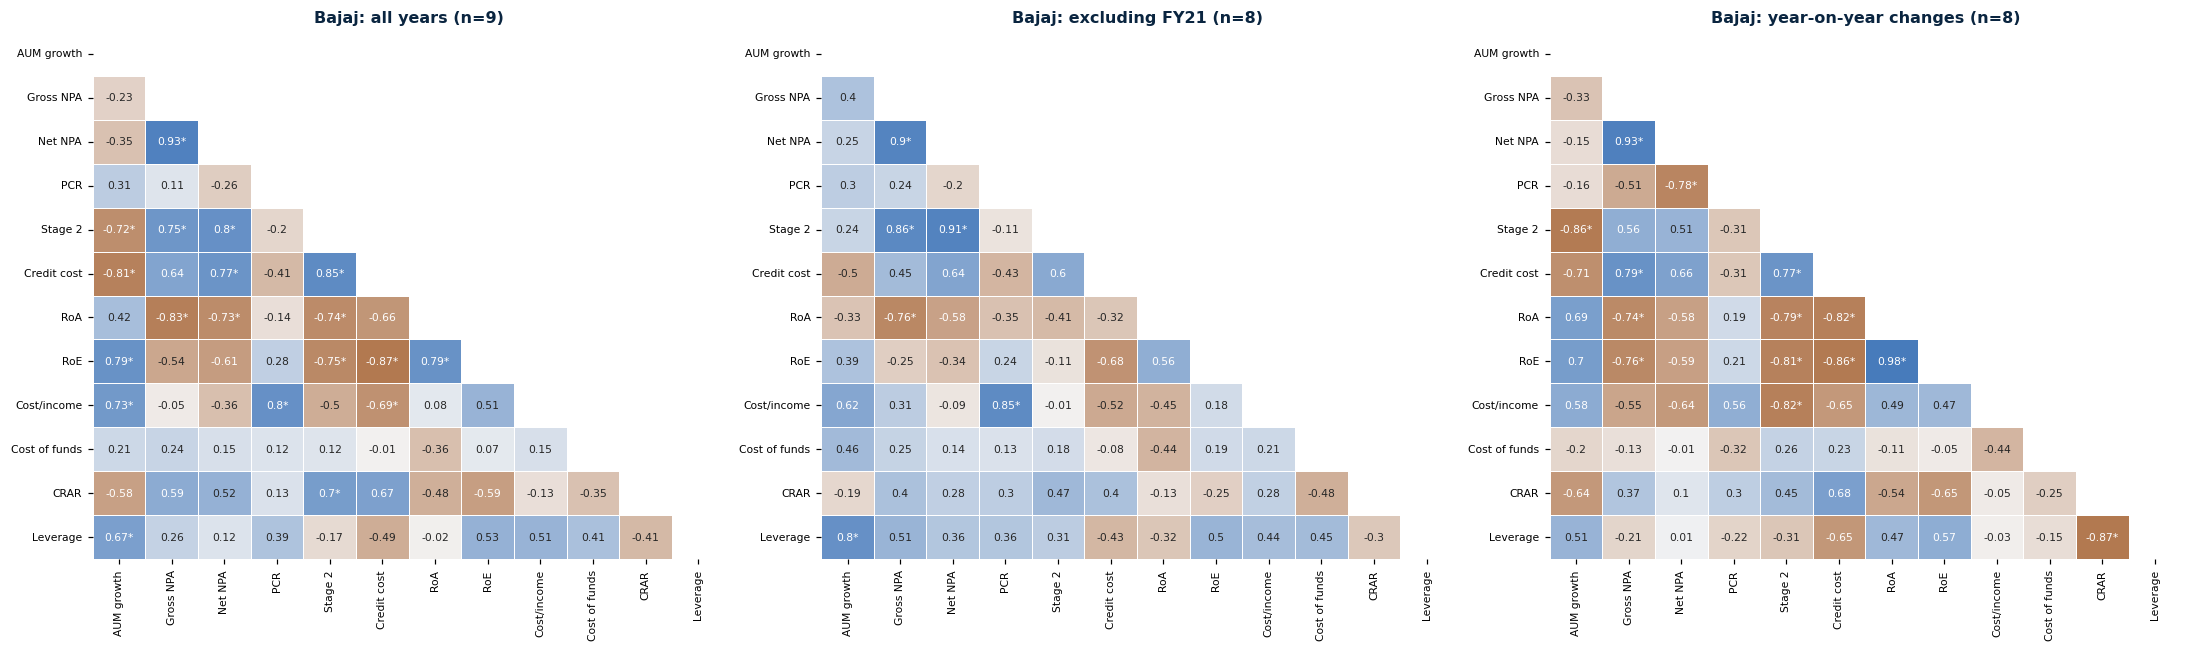

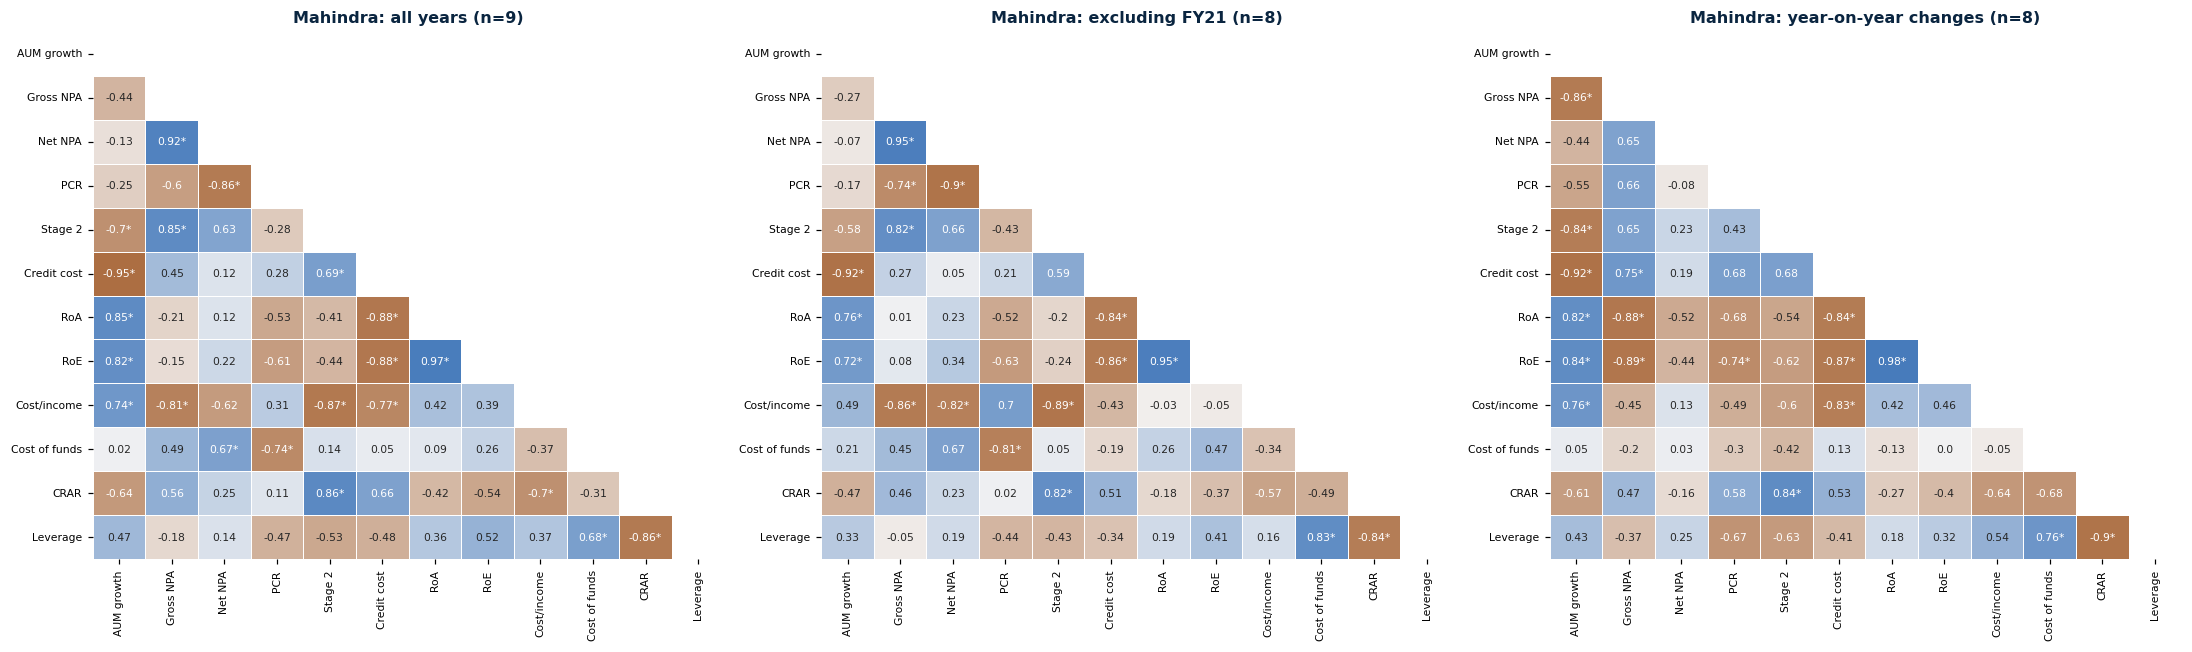

,Company,Pair,All years,Ex FY21,YoY changes
0,Bajaj,AUM growth vs Credit cost,-0.81,-0.50,-0.71
1,Bajaj,Credit cost vs RoE,-0.87,-0.68,-0.86
2,Bajaj,Credit cost vs RoA,-0.66,-0.32,-0.82
3,Bajaj,Stage 2 vs Credit cost,0.85,0.60,0.77
4,Bajaj,Gross NPA vs PCR,0.11,0.24,-0.51
5,Bajaj,Cost/income vs RoE,0.51,0.18,0.47
6,Mahindra,AUM growth vs Credit cost,-0.95,-0.92,-0.92
7,Mahindra,Credit cost vs RoE,-0.88,-0.86,-0.87
8,Mahindra,Credit cost vs RoA,-0.88,-0.84,-0.84
9,Mahindra,Stage 2 vs Credit cost,0.69,0.59,0.68


In [ ]:
for co in COS:
    fig, ax = plt.subplots(1, 3, figsize=(20, 6))
    for a, (k, t) in zip(ax, [("all", "all years (n=9)"), ("ex21", "excluding FY21 (n=8)"), ("diff", "year-on-year changes (n=8)")]):
        heat(a, *CORR[co][k], f"{SHORT[co]}: {t}")
    savefig(f"D1_corr_{SHORT[co]}")

# Which headline relationships are stable?
KEY = [("g", "cc"), ("cc", "roe"), ("cc", "roa"), ("s2", "cc"), ("gnpa", "pcr"), ("cir", "roe")]
rows = []
for co in COS:
    for a_, b_ in KEY:
        rows.append({"Company": SHORT[co], "Pair": f"{LABEL[a_]} vs {LABEL[b_]}", "All years": CORR[co]["all"][0].loc[a_, b_],
                     "Ex FY21": CORR[co]["ex21"][0].loc[a_, b_], "YoY changes": CORR[co]["diff"][0].loc[a_, b_]})
display(pd.DataFrame(rows).round(2))

In [ ]:
# D2. Lead-lag: variable at t versus another variable at t+1
LL = [("s2", "gnpa"), ("s2", "cc"), ("gnpa", "cc"), ("g", "cc"), ("g", "gnpa"), ("cc", "roa")]
rows = []
for co in COS:
    d = C(co).loc[IND_YEARS]
    for x_, y_ in LL:
        a_ = d[x_].iloc[:-1].values; b_ = d[y_].iloc[1:].values; r, p = stats.pearsonr(a_, b_)
        rows.append({"Company": SHORT[co], "Lead": f"{LABEL[x_]}(t) -> {LABEL[y_]}(t+1)", "r": r, "p": p, "n": len(a_)})
ll = pd.DataFrame(rows); display(ll.round(2))
print("None of these should be read as predictive evidence unless p is small and the sign is stable in both firms; n = 8 per firm.")

,Company,Lead,r,p,n
0,Bajaj,Stage 2(t) -> Gross NPA(t+1),0.49,0.22,8
1,Bajaj,Stage 2(t) -> Credit cost(t+1),0.37,0.36,8
2,Bajaj,Gross NPA(t) -> Credit cost(t+1),0.40,0.32,8
3,Bajaj,AUM growth(t) -> Credit cost(t+1),-0.15,0.72,8
4,Bajaj,AUM growth(t) -> Gross NPA(t+1),-0.07,0.86,8
5,Bajaj,Credit cost(t) -> RoA(t+1),-0.29,0.48,8
6,Mahindra,Stage 2(t) -> Gross NPA(t+1),0.51,0.20,8
7,Mahindra,Stage 2(t) -> Credit cost(t+1),0.21,0.62,8
8,Mahindra,Gross NPA(t) -> Credit cost(t+1),0.36,0.38,8
9,Mahindra,AUM growth(t) -> Credit cost(t+1),-0.39,0.34,8


None of these should be read as predictive evidence unless p is small and the sign is stable in both firms; n = 8 per firm.


## Part E. Segment analysis

The `Segments` sheet gives segment AUM, risk tier, secured type and (for some rows) segment GNPA. **Important:** Mahindra's segment GNPA and 47 of Bajaj's 100 segment rows are *allocated by the compiler*, not reported, so segment-level GNPA is only analysed where it is flagged "Reported".

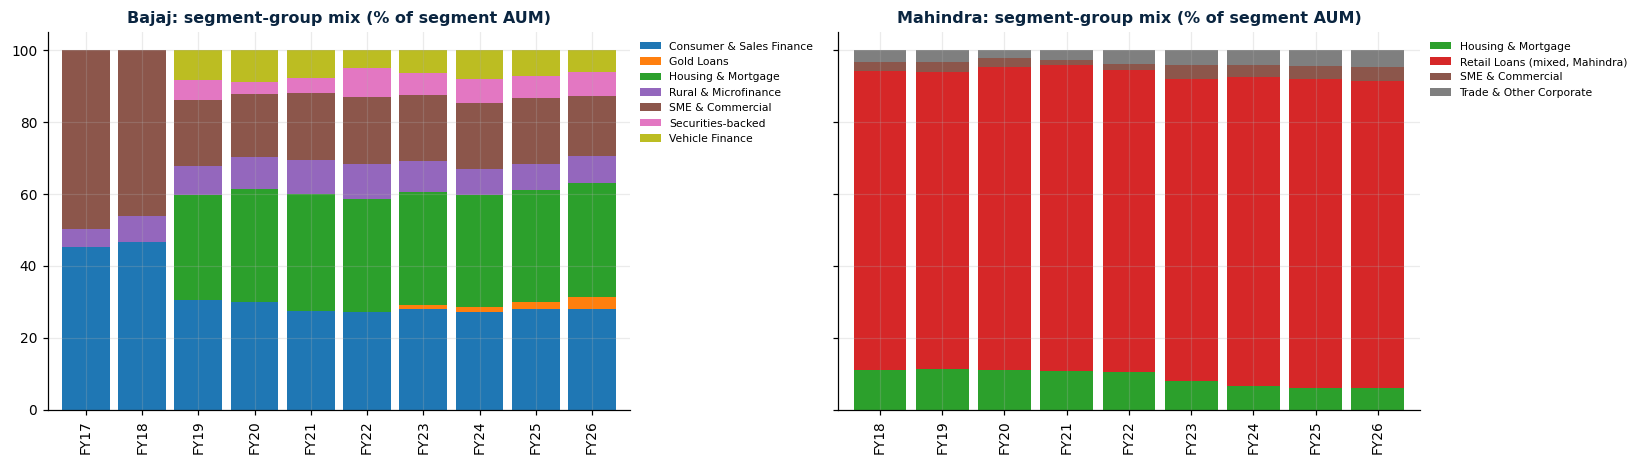

In [ ]:
# E1. Segment-group mix of both companies side by side
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
groups = sorted(SEG.Segment_Group.unique()); pal = dict(zip(groups, sns.color_palette("tab10", len(groups))))
for a, co in zip(ax, COS):
    m = seg_mix(co); m.plot(kind="bar", stacked=True, ax=a, color=[pal[g] for g in m.columns], width=.85)
    a.set_title(f"{SHORT[co]}: segment-group mix (% of segment AUM)"); a.set_xlabel(""); a.legend(fontsize=7, bbox_to_anchor=(1, 1))
savefig("E1_segment_mix")

In [ ]:
# E2. Mahindra product growth and contribution to growth (FY18 -> FY26, from the Segments sheet)
mp = SEG[SEG.Company == "Mahindra Finance"].pivot_table(index="Segment", columns="y", values="Segment_AUM", aggfunc="sum")
tab = pd.DataFrame({"FY18 (Rs Cr)": mp["FY18"], "FY26 (Rs Cr)": mp["FY26"]})
tab["CAGR % (8y)"] = np.where(mp["FY18"] > 0, ((mp["FY26"] / mp["FY18"].replace(0, np.nan)) ** (1 / 8) - 1) * 100, np.nan)
tab["Share of FY18 book %"] = mp["FY18"] / mp["FY18"].sum() * 100
tab["Share of FY26 book %"] = mp["FY26"] / mp["FY26"].sum() * 100
tab["Share of growth %"] = (mp["FY26"] - mp["FY18"]) / (mp["FY26"].sum() - mp["FY18"].sum()) * 100
display(tab.round(1))
hhi = lambda y: ((mp[y] / mp[y].sum() * 100) ** 2).sum()
print(f"Concentration (HHI of product shares): FY18 {hhi('FY18'):.0f} -> FY26 {hhi('FY26'):.0f}. 'NaN' CAGR = product had no balance in FY18 (finance lease starts later).")

# E3. Bajaj: contribution of segment groups to AUM growth, FY19 -> FY26 (taxonomy A to C; groups are harmonised)
bg = SEG[SEG.Company == "Bajaj Finance"].pivot_table(index="Segment_Group", columns="y", values="Segment_AUM", aggfunc="sum").fillna(0)
t2 = pd.DataFrame({"FY19": bg["FY19"], "FY26": bg["FY26"]}); t2["CAGR % (7y)"] = np.where(t2.FY19 > 0, ((t2.FY26 / t2.FY19.replace(0, np.nan)) ** (1 / 7) - 1) * 100, np.nan)
t2["Share of growth %"] = (t2.FY26 - t2.FY19) / (t2.FY26.sum() - t2.FY19.sum()) * 100
display(t2.round(1))

,FY18 (Rs Cr),FY26 (Rs Cr),CAGR % (8y),Share of FY18 book %,Share of FY26 book %,Share of growth %
Segment,,,,,,
Bills of exchange,550.3,2349.5,19.9,1.0,1.6,2.1
Finance lease,0.0,1229.0,NaN,0.0,0.9,1.4
Housing finance,6312.2,8512.2,3.8,10.9,5.9,2.6
Retail loans,48169.6,122410.4,12.4,83.3,85.4,86.8
SME financing,1360.5,5740.6,19.7,2.4,4.0,5.1
Trade advances,1437.3,3163.2,10.4,2.5,2.2,2.0


Concentration (HHI of product shares): FY18 7070 -> FY26 7346. 'NaN' CAGR = product had no balance in FY18 (finance lease starts later).


,FY19,FY26,CAGR % (7y),Share of growth %
Segment_Group,,,,
Consumer & Sales Finance,35263.0,141915.0,22.0,27.1
Gold Loans,0.0,17831.0,NaN,4.5
Housing & Mortgage,33870.0,162077.0,25.1,32.5
Rural & Microfinance,9243.0,37991.0,22.4,7.3
SME & Commercial,21427.0,85409.0,21.8,16.2
Securities-backed,6359.0,33247.0,26.7,6.8
Vehicle Finance,9726.0,31505.0,18.3,5.5


Reported segment-GNPA rows by company: {'Bajaj Finance': 53} | allocated rows: {'Bajaj Finance': 47, 'Mahindra Finance': 54}


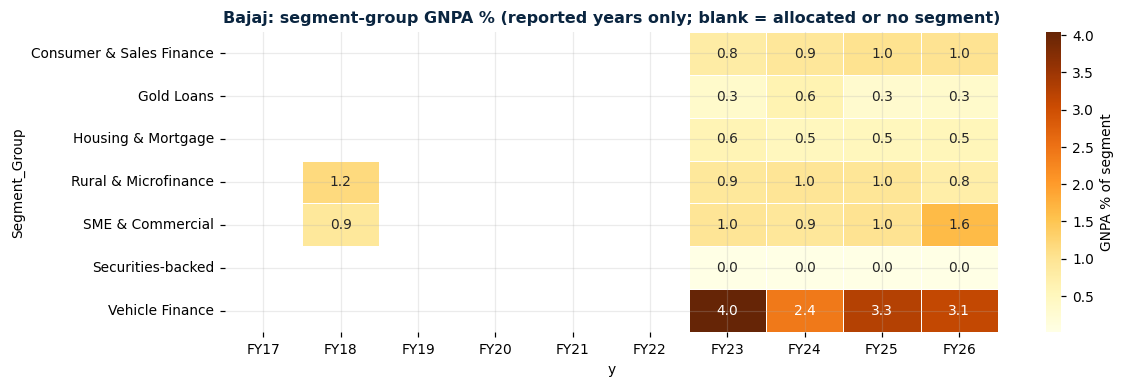

In [ ]:
# E4. Segment GNPA where it is REPORTED (not allocated)
rep_ = SEG[SEG.Segment_GNPA_basis == "Reported"].copy()
rep_["gn_amt"] = rep_.Segment_GNPA_amt
g = rep_.groupby(["Company", "Segment_Group", "y"]).agg(gn=("gn_amt", "sum"), aum=("Segment_AUM", "sum")).reset_index()
g["gnpa_pct"] = g.gn / g.aum * 100
print("Reported segment-GNPA rows by company:", rep_.groupby("Company").size().to_dict(), "| allocated rows:", SEG[SEG.Segment_GNPA_basis != "Reported"].groupby("Company").size().to_dict())
hb = g[g.Company == "Bajaj Finance"].pivot(index="Segment_Group", columns="y", values="gnpa_pct").reindex(columns=YEARS)
fig, ax = plt.subplots(figsize=(11, 3.6)); sns.heatmap(hb, annot=True, fmt=".1f", cmap="YlOrBr", linewidths=.5, ax=ax, cbar_kws={"label": "GNPA % of segment"})
ax.set_title("Bajaj: segment-group GNPA % (reported years only; blank = allocated or no segment)"); savefig("E4_bajaj_segment_gnpa")

In [ ]:
# E5. Does mix move with asset quality?  Levels versus year-on-year changes
def mix_corr(co, years):
    d = C(co).loc[years]; rows = []
    for m in ["hr", "uns"]:
        for t in ["gnpa", "cc", "s2"]:
            r1, p1 = stats.pearsonr(d[m], d[t]); dd = d[[m, t]].diff().dropna(); r2, p2 = stats.pearsonr(dd[m], dd[t])
            flag = "possible trend artefact" if abs(r1) >= .6 and abs(r2) < .4 else ("holds in changes" if abs(r2) >= .6 else "")
            rows.append({"Company": SHORT[co], "Mix variable": {"hr": "High-risk share", "uns": "Unsecured share"}[m], "vs": LABEL[t], "r (levels)": r1, "p": p1, "r (changes)": r2, "p (chg)": p2, "n": len(d), "Reading": flag})
    return rows
rows = mix_corr("Bajaj Finance", [y for y in YEARS if y >= "FY19"]) + mix_corr("Mahindra Finance", [y for y in YEARS if y >= "FY18"])
display(pd.DataFrame(rows).round(2))
print("Bajaj window FY19-FY26 (comparable taxonomy). Mahindra window FY18-FY26. Segment-derived shares depend on analyst risk labels.")
print("Caution: Mahindra's unsecured share is built from SME, bills and trade advances (about 8% of the book) with Mixed counted at 50%. Its negative link with credit cost mainly reflects that small share rising while credit cost normalised after COVID; it is not evidence that unsecured lending lowers losses.")

# E6. Cross-check against the clean segment workbook produced earlier (Mahindra product totals)
try:
    cl = pd.read_excel(find(SEG_CLEAN_FILE), sheet_name="Mahindra_Product_Mix", header=3).iloc[:10]
    cl["y"] = cl["Financial year"].map(yshort)
    a = cl.set_index("y")["Total (Rs Cr)"].astype(float); b = SEG[SEG.Company == "Mahindra Finance"].groupby("y").Segment_AUM.sum()
    cmp_ = pd.DataFrame({"clean workbook": a, "merged Segments": b}).dropna(); cmp_["diff"] = cmp_.iloc[:, 0] - cmp_.iloc[:, 1]
    display(cmp_.round(2)); print("Max absolute difference (Rs Cr):", round(cmp_["diff"].abs().max(), 2))
except Exception as e:
    print("Cross-check skipped:", e)

,Company,Mix variable,vs,r (levels),p,r (changes),p (chg),n,Reading
0,Bajaj,High-risk share,Gross NPA,0.76,0.03,-0.08,0.86,8,possible trend artefact
1,Bajaj,High-risk share,Credit cost,0.40,0.33,0.46,0.30,8,
2,Bajaj,High-risk share,Stage 2,0.64,0.09,0.32,0.48,8,possible trend artefact
3,Bajaj,Unsecured share,Gross NPA,0.84,0.01,0.14,0.76,8,possible trend artefact
4,Bajaj,Unsecured share,Credit cost,0.34,0.41,0.14,0.76,8,
5,Bajaj,Unsecured share,Stage 2,0.53,0.18,-0.20,0.67,8,
6,Mahindra,High-risk share,Gross NPA,0.81,0.01,-0.25,0.55,9,possible trend artefact
7,Mahindra,High-risk share,Credit cost,0.06,0.88,-0.41,0.32,9,
8,Mahindra,High-risk share,Stage 2,0.64,0.06,-0.02,0.95,9,possible trend artefact
9,Mahindra,Unsecured share,Gross NPA,-0.83,0.01,-0.76,0.03,9,holds in changes


Bajaj window FY19-FY26 (comparable taxonomy). Mahindra window FY18-FY26. Segment-derived shares depend on analyst risk labels.
Caution: Mahindra's unsecured share is built from SME, bills and trade advances (about 8% of the book) with Mixed counted at 50%. Its negative link with credit cost mainly reflects that small share rising while credit cost normalised after COVID; it is not evidence that unsecured lending lowers losses.


,clean workbook,merged Segments,diff
y,,,
FY18,57832.52,57829.85,2.67
FY19,71161.53,71160.41,1.12
FY20,76520.32,76519.09,1.23
FY21,72239.57,72238.38,1.19
FY22,72741.07,72740.90,0.17
FY23,90105.36,90105.25,0.11
FY24,110025.82,110025.74,0.08
FY25,127588.41,127588.36,0.05
FY26,143405.14,143404.84,0.30


Max absolute difference (Rs Cr): 2.67


## Part F. Credit Risk Index: construction

**Idea.** Combine the credit-risk indicators into one 0-100 score per company-year (**higher = riskier**), with a method that is transparent and does not depend on the two companies' own averages.

**Design choices (and why)**

- **Three pillars**, because the PCA exploration showed two distinct dimensions: a *stock* of bad assets and a *flow* of losses. We add a *buffer* pillar for loss absorption.
  - Pillar 1, Asset quality: gross NPA, net NPA, Stage 2
  - Pillar 2, Loss experience: credit cost, loan losses over NTI
  - Pillar 3, Loss absorption: PCR (lower coverage = riskier) and CRAR headroom over the RBI 15% floor
- **Fixed thresholds** (score 0 = best, 100 = worst, linear between, capped), so a score means the same thing across companies and years.
- **Equal pillar weights** as the base case; alternatives are tested in Part G.
- **Unsecured share is excluded** from the index: it is a driver of risk, not an outcome. We use it afterwards to explain differences.
- **Window:** Ind AS years only (FY18 to FY26). FY17 is pre-Ind AS and its stage data are estimated.

**The thresholds are analyst judgement** anchored to common rating-style ranges. Part G tests how much the results depend on them. Replace them with a cited source if your report requires one.

In [ ]:
THRESH = {  # variable: (pillar, level scored 0 = best, level scored 100 = worst)
    "gnpa":  ("Asset quality", 1.0, 8.0),
    "nnpa":  ("Asset quality", 0.5, 4.0),
    "s2":    ("Asset quality", 1.0, 12.0),
    "cc":    ("Loss experience", 1.0, 5.0),
    "llnti": ("Loss experience", 10.0, 50.0),
    "pcr":   ("Loss absorption", 70.0, 30.0),    # reversed: low coverage is worse
    "cap":   ("Loss absorption", 10.0, 0.0),     # CRAR headroom over 15%, in pp; reversed
}
PILLARS = {"Asset quality": ["gnpa", "nnpa", "s2"], "Loss experience": ["cc", "llnti"], "Loss absorption": ["pcr", "cap"]}
display(pd.DataFrame([(LABEL.get(k, k), v[0], v[1], v[2]) for k, v in THRESH.items()], columns=["Input", "Pillar", "Score 0 at", "Score 100 at"]))

def score(d, mult=1.0, use_cap=True):
    # 0-100 risk score per input. mult scales how far the worst-case bound sits from the best (1 = base)
    out = {}
    for v, (_, b, w) in THRESH.items():
        if v == "cap" and not use_cap: continue
        w2 = b + (w - b) * mult
        out[v] = ((d[v] - b) / (w2 - b)).clip(0, 1) * 100
    return pd.DataFrame(out)

def pillar_scores(s):
    return pd.DataFrame({p: s[[v for v in vs if v in s]].mean(axis=1) for p, vs in PILLARS.items()})

def risk_index(d, w=(1/3, 1/3, 1/3), **kw):
    return (pillar_scores(score(d, **kw)) * np.array(w)).sum(axis=1)

IDXD = {co: C(co).loc[IND_YEARS] for co in COS}
SC = {co: score(IDXD[co]) for co in COS}
PL = {co: pillar_scores(SC[co]) for co in COS}
BASE = pd.DataFrame({SHORT[co]: risk_index(IDXD[co]) for co in COS})
display(BASE.round(1).T)

,Input,Pillar,Score 0 at,Score 100 at
0,Gross NPA,Asset quality,1.0,8.0
1,Net NPA,Asset quality,0.5,4.0
2,Stage 2,Asset quality,1.0,12.0
3,Credit cost,Loss experience,1.0,5.0
4,Loss/NTI,Loss experience,10.0,50.0
5,PCR,Loss absorption,70.0,30.0
6,CRAR headroom,Loss absorption,10.0,0.0


y,FY18,FY19,FY20,FY21,FY22,FY23,FY24,FY25,FY26
Bajaj,4.4,16.7,20.6,33.2,19.7,5.0,13.4,20.1,18.8
Mahindra,56.6,55.4,76.5,73.6,63.2,33.3,36.1,38.2,33.1


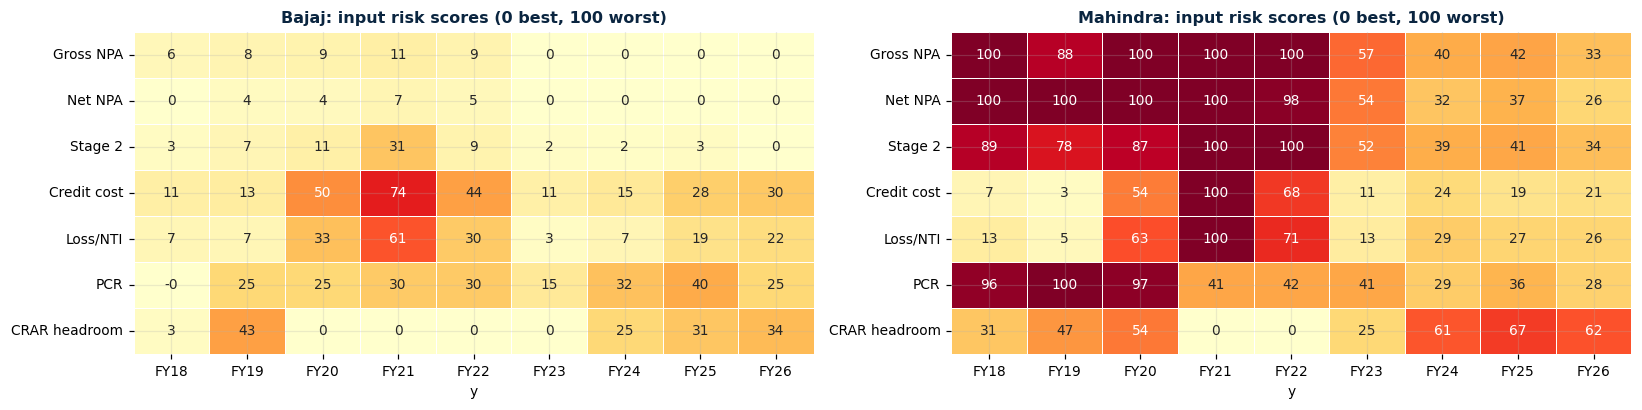

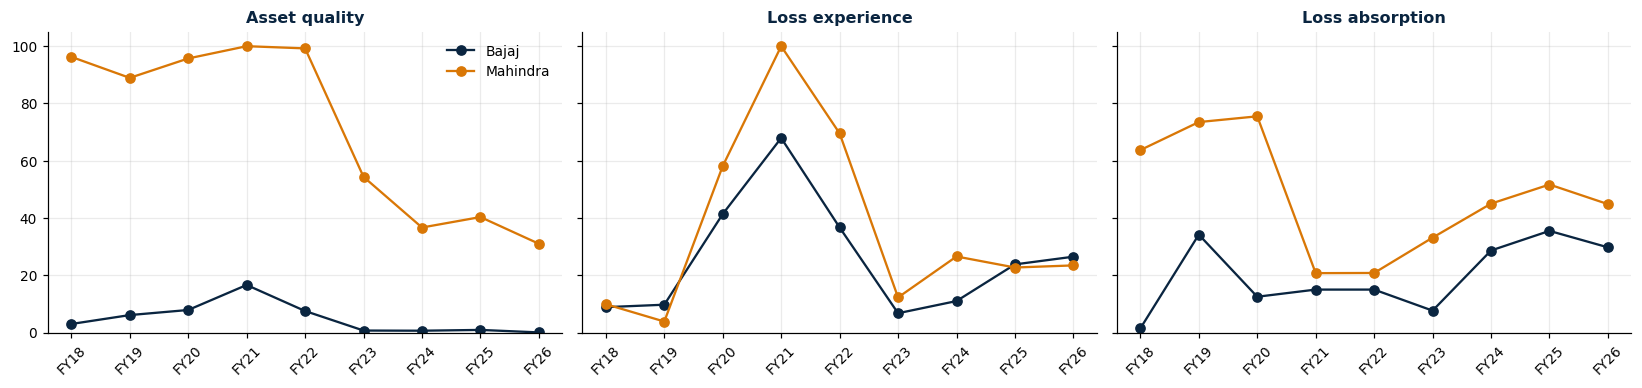

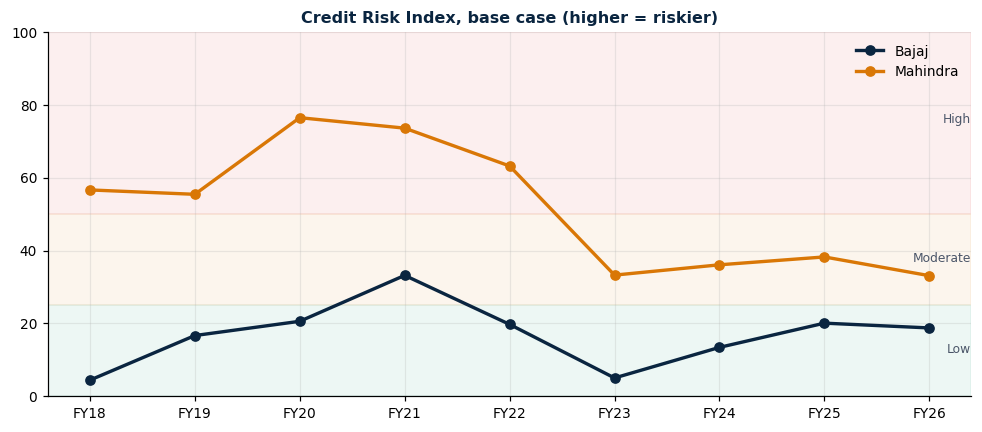

In [ ]:
# F2. Input-level scores: which inputs drive each company's index?
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
for a, co in zip(ax, COS):
    sns.heatmap(SC[co].T.rename(index=LABEL), annot=True, fmt=".0f", cmap="YlOrRd", vmin=0, vmax=100, linewidths=.5, ax=a, cbar=False)
    a.set_title(f"{SHORT[co]}: input risk scores (0 best, 100 worst)")
savefig("F2_input_scores")

# F3. Pillar trajectories
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for a, p in zip(ax, PILLARS):
    for co in COS: a.plot(IND_YEARS, PL[co][p], marker="o", color=COL[co], label=SHORT[co])
    a.set_title(p); a.set_ylim(0, 105); a.tick_params(axis="x", rotation=45)
ax[0].legend(); savefig("F3_pillars")

# F4. Base-case index
fig, ax = plt.subplots(figsize=(9, 4))
for co in COS: ax.plot(IND_YEARS, BASE[SHORT[co]], marker="o", lw=2.2, color=COL[co], label=SHORT[co])
ax.axhspan(0, 25, color=EM, alpha=.07); ax.axhspan(25, 50, color=AMB, alpha=.07); ax.axhspan(50, 100, color=RED, alpha=.07)
for yv, t in [(12, "Low"), (37, "Moderate"), (75, "High")]: ax.text(len(IND_YEARS) - .6, yv, t, color=SLATE, fontsize=8, ha="right")
ax.set_ylim(0, 100); ax.set_title("Credit Risk Index, base case (higher = riskier)"); ax.legend(); savefig("F4_base_index")

## Part G. Credit Risk Index: comparison, sensitivity and robustness

Questions answered here:

1. Which company scores riskier, and by how much?
2. **Why** (which pillar explains the gap)?
3. Does the ranking survive different weights, thresholds, a PCA-based weighting and non-compensatory aggregation?
4. How wide is the uncertainty (Monte Carlo)?
5. Is there any sign that the index leads next-year credit cost?

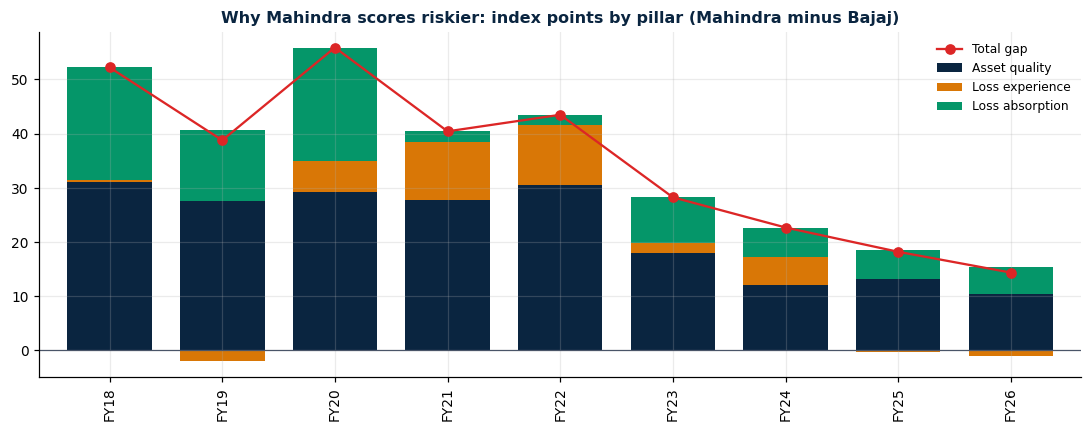

Base case: Mahindra scores riskier than Bajaj in **9 of 9** years. FY26: Bajaj **18.8**, Mahindra **33.1**. Mahindra's score fell from 76.5 (FY20) to 33.1; Bajaj's moved from a low of 4.4 (FY18) to 18.8.

In [ ]:
# G1. Gap decomposition: Mahindra minus Bajaj, by pillar (equal weights, so each pillar contributes diff/3)
diff_p = (PL["Mahindra Finance"] - PL["Bajaj Finance"]) / 3
fig, ax = plt.subplots(figsize=(10, 4))
diff_p.plot(kind="bar", stacked=True, ax=ax, color=[NAVY, AMB, EM], width=.75)
ax.plot(range(len(IND_YEARS)), BASE["Mahindra"] - BASE["Bajaj"], color=RED, marker="o", label="Total gap"); ax.axhline(0, color=SLATE, lw=.8)
ax.set_title("Why Mahindra scores riskier: index points by pillar (Mahindra minus Bajaj)"); ax.legend(fontsize=8); ax.set_xlabel("")
savefig("G1_gap_decomposition")
yrs_m = int((BASE["Mahindra"] > BASE["Bajaj"]).sum())
display(Markdown(f"Base case: Mahindra scores riskier than Bajaj in **{yrs_m} of {len(IND_YEARS)}** years. FY26: Bajaj **{BASE.Bajaj['FY26']:.1f}**, Mahindra **{BASE.Mahindra['FY26']:.1f}**. "
                 f"Mahindra's score fell from {BASE.Mahindra.max():.1f} ({BASE.Mahindra.idxmax()}) to {BASE.Mahindra['FY26']:.1f}; Bajaj's moved from a low of {BASE.Bajaj.min():.1f} ({BASE.Bajaj.idxmin()}) to {BASE.Bajaj['FY26']:.1f}."))

In [ ]:
# G2. Scenario analysis (weights and thresholds), plus a PCA-weighted variant
SCEN = {
    "Base case (equal weights)": dict(),
    "Asset-quality heavy (50/25/25)": dict(w=(.5, .25, .25)),
    "Loss-flow heavy (25/50/25)": dict(w=(.25, .5, .25)),
    "Buffer heavy (25/25/50)": dict(w=(.25, .25, .5)),
    "PCR-only buffer (no capital)": dict(use_cap=False),
    "Tighter thresholds (x0.75)": dict(mult=.75),
    "Looser thresholds (x1.25)": dict(mult=1.25),
}
RES = {n: pd.DataFrame({SHORT[co]: risk_index(IDXD[co], **kw) for co in COS}) for n, kw in SCEN.items()}

# PCA weights on the pooled scored inputs (relative to this sample, rescaled 0-100)
S = pd.concat([SC[co] for co in COS]); Z = (S - S.mean()) / S.std(ddof=0)
w_, v_ = np.linalg.eigh(np.corrcoef(Z.T.values)); pc = Z.values @ v_[:, w_.argmax()]
base_all = np.concatenate([BASE.Bajaj.values, BASE.Mahindra.values])
if np.corrcoef(pc, base_all)[0, 1] < 0: pc = -pc
pc = (pc - pc.min()) / (pc.max() - pc.min()) * 100
n_ = len(IND_YEARS); RES["PCA weights (relative)"] = pd.DataFrame({"Bajaj": pc[:n_], "Mahindra": pc[n_:]}, index=IND_YEARS)
print(f"PCA: PC1 explains {w_.max()/w_.sum()*100:.0f}% of variance of the 7 scored inputs. Loadings on PC1:")
display(pd.Series(v_[:, w_.argmax()] * np.sign(np.corrcoef(Z.values @ v_[:, w_.argmax()], base_all)[0, 1]), index=[LABEL.get(k, k) for k in S.columns]).round(2).to_frame("loading").T)

# Non-compensatory variants: a strong pillar cannot hide a weak one
def noncomp(f): return pd.DataFrame({SHORT[co]: f(PL[co]) for co in COS})
RES["Worst pillar (non-compensatory)"] = noncomp(lambda p: p.max(axis=1))
RES["Geometric mean (non-compensatory)"] = noncomp(lambda p: np.exp(np.log(p + 1).mean(axis=1)) - 1)

summ = pd.DataFrame([{"Scenario": n, "Bajaj FY26": r.Bajaj["FY26"], "Mahindra FY26": r.Mahindra["FY26"], "Bajaj FY21": r.Bajaj["FY21"], "Mahindra FY21": r.Mahindra["FY21"],
                      "Years Mahindra riskier": f"{int((r.Mahindra > r.Bajaj).sum())}/{len(r)}", "Peak yr B / M": f"{r.Bajaj.idxmax()} / {r.Mahindra.idxmax()}"} for n, r in RES.items()])
display(summ.round(1))

PCA: PC1 explains 58% of variance of the 7 scored inputs. Loadings on PC1:


,Gross NPA,Net NPA,Stage 2,Credit cost,Loss/NTI,PCR,CRAR headroom
loading,0.48,0.48,0.49,0.23,0.33,0.37,0.05


,Scenario,Bajaj FY26,Mahindra FY26,Bajaj FY21,Mahindra FY21,Years Mahindra riskier,Peak yr B / M
0,Base case (equal weights),18.8,33.1,33.2,73.6,9/9,FY21 / FY20
1,Asset-quality heavy (50/25/25),14.1,32.6,29.0,80.2,9/9,FY21 / FY20
2,Loss-flow heavy (25/50/25),20.7,30.7,41.9,80.2,9/9,FY21 / FY21
3,Buffer heavy (25/25/50),21.5,36.0,28.6,60.4,9/9,FY21 / FY20
4,PCR-only buffer (no capital),17.2,27.4,38.2,80.5,9/9,FY21 / FY20
5,Tighter thresholds (x0.75),25.0,44.1,44.2,75.9,9/9,FY21 / FY20
6,Looser thresholds (x1.25),15.0,26.5,26.5,67.9,9/9,FY21 / FY21
7,PCA weights (relative),10.8,30.4,35.6,100.0,9/9,FY21 / FY21
8,Worst pillar (non-compensatory),29.7,44.8,67.9,100.0,9/9,FY21 / FY21
9,Geometric mean (non-compensatory),8.6,32.0,25.9,59.5,9/9,FY21 / FY20


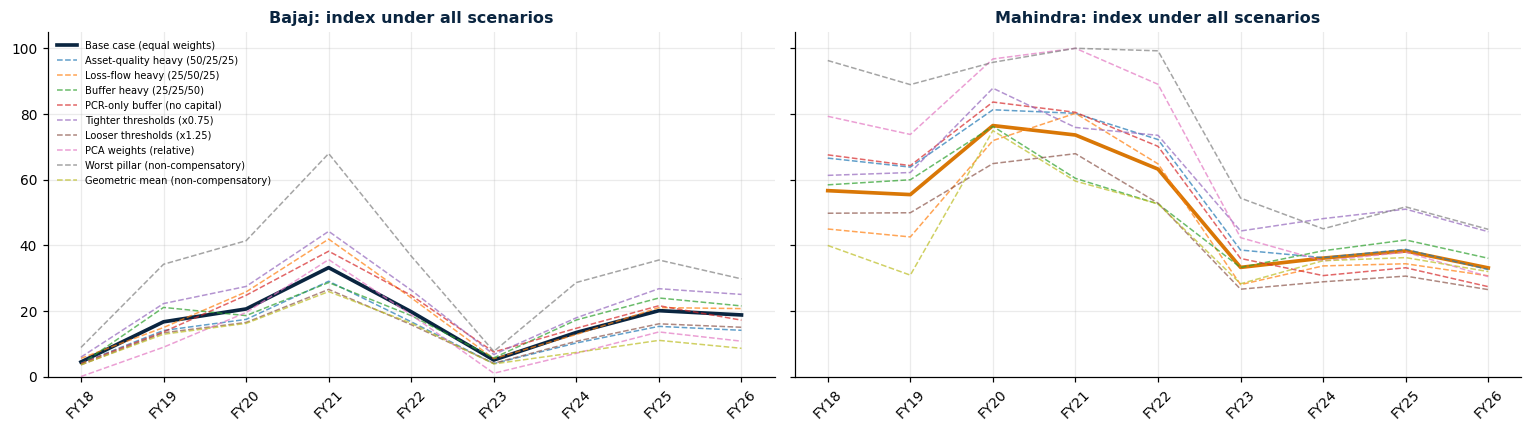

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a, co in zip(ax, ["Bajaj", "Mahindra"]):
    for i, (n, r) in enumerate(RES.items()):
        a.plot(IND_YEARS, r[co], lw=2.4 if i == 0 else 1, ls="-" if i == 0 else "--", color=NAVY if (co == "Bajaj" and i == 0) else AMB if i == 0 else None, alpha=1 if i == 0 else .7, label=n if co == "Bajaj" else None)
    a.set_title(f"{co}: index under all scenarios"); a.set_ylim(0, 105); a.tick_params(axis="x", rotation=45)
ax[0].legend(fontsize=6.5, loc="upper left"); savefig("G2_scenarios")

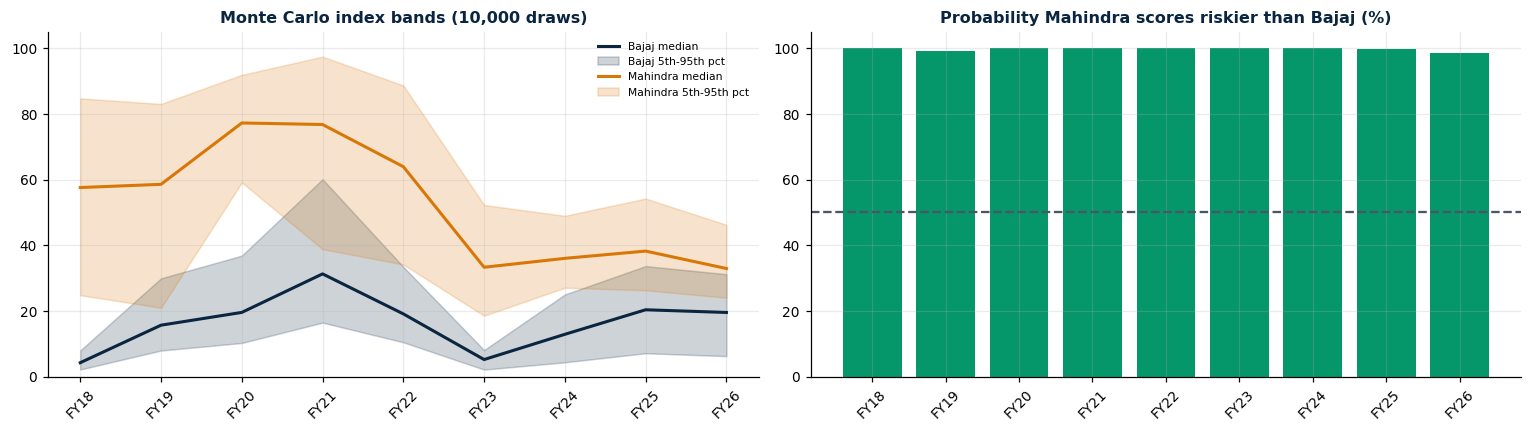

Mahindra riskier in at least 98% of draws in every year (98.5% lowest, FY26).
Years where the 5th-95th percentile bands overlap (level gap is uncertain even though the ranking is stable): ['FY19', 'FY21', 'FY25', 'FY26']


In [ ]:
# G3. Monte Carlo: random pillar weights (Dirichlet) and random threshold stringency (+/-25%)
rng = np.random.default_rng(SEED)
W = rng.dirichlet([1, 1, 1], MC_DRAWS); MU = rng.uniform(.75, 1.25, MC_DRAWS)
def mc(co):
    d = IDXD[co]; out = []
    for p, vs in PILLARS.items():
        acc = 0
        for v in vs:
            _, b, w = THRESH[v]; w2 = b + (w - b) * MU[:, None]
            acc = acc + np.clip((d[v].values[None, :] - b) / (w2 - b), 0, 1) * 100
        out.append(acc / len(vs))
    return W[:, [0]] * out[0] + W[:, [1]] * out[1] + W[:, [2]] * out[2]
MB, MM = mc("Bajaj Finance"), mc("Mahindra Finance")
q = lambda a, p: np.percentile(a, p, axis=0)
prob = (MM > MB).mean(axis=0) * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for M_, co in [(MB, "Bajaj Finance"), (MM, "Mahindra Finance")]:
    ax[0].plot(IND_YEARS, q(M_, 50), color=COL[co], lw=2, label=f"{SHORT[co]} median"); ax[0].fill_between(IND_YEARS, q(M_, 5), q(M_, 95), color=COL[co], alpha=.2, label=f"{SHORT[co]} 5th-95th pct")
ax[0].set_title(f"Monte Carlo index bands ({MC_DRAWS:,} draws)"); ax[0].legend(fontsize=7); ax[0].set_ylim(0, 105); ax[0].tick_params(axis="x", rotation=45)
ax[1].bar(IND_YEARS, prob, color=EM); ax[1].axhline(50, color=SLATE, ls="--"); ax[1].set_ylim(0, 105); ax[1].set_title("Probability Mahindra scores riskier than Bajaj (%)"); ax[1].tick_params(axis="x", rotation=45)
savefig("G3_monte_carlo")
print(f"Mahindra riskier in at least {prob.min():.0f}% of draws in every year ({prob.min():.1f}% lowest, {IND_YEARS[int(prob.argmin())]}).")
ov = [y for y, lo_m, hi_b in zip(IND_YEARS, q(MM, 5), q(MB, 95)) if lo_m < hi_b]
print("Years where the 5th-95th percentile bands overlap (level gap is uncertain even though the ranking is stable):", ov)

In [ ]:
# G4. Validation and sanity checks
# (a) Does the non-loss-flow part of the index (pillars 1 and 3) at t track credit cost at t+1?
rows = []
for co in COS:
    p = PL[co]; x = ((p["Asset quality"] + p["Loss absorption"]) / 2).values[:-1]; y = IDXD[co].cc.values[1:]
    r, pv = stats.pearsonr(x, y); rows.append({"Company": SHORT[co], "r (index_t vs credit cost_t+1)": r, "p": pv, "n": len(x)})
xp = np.concatenate([((PL[co]["Asset quality"] + PL[co]["Loss absorption"]) / 2).values[:-1] for co in COS]); yp = np.concatenate([IDXD[co].cc.values[1:] for co in COS])
r, pv = stats.pearsonr(xp, yp); rows.append({"Company": "Pooled", "r (index_t vs credit cost_t+1)": r, "p": pv, "n": len(xp)})
display(pd.DataFrame(rows).round(2))
# (b) Does the index move with a simple single indicator (gross NPA)?
for co in COS:
    r, pv = stats.pearsonr(BASE[SHORT[co]], IDXD[co].gnpa); print(f"{SHORT[co]}: correlation of base index with gross NPA = {r:.2f}")
# (c) Stress-year behaviour
for co in COS: print(f"{SHORT[co]}: index peaks in {BASE[SHORT[co]].idxmax()} ({BASE[SHORT[co]].max():.1f})")

,Company,r (index_t vs credit cost_t+1),p,n
0,Bajaj,0.43,0.28,8
1,Mahindra,0.50,0.20,8
2,Pooled,0.30,0.26,16


Bajaj: correlation of base index with gross NPA = 0.51
Mahindra: correlation of base index with gross NPA = 0.89
Bajaj: index peaks in FY21 (33.2)
Mahindra: index peaks in FY20 (76.5)


In [ ]:
# G5. Reconciliation with the earlier dashboard (which used the original source files)
DASH = {"Bajaj": {"FY21": 33.9, "FY26": 19.0}, "Mahindra": {"FY21": 73.6, "FY26": 33.1}}
rows = [{"Company": c, "Year": y, "Dashboard (earlier data)": v, "This notebook (merged file)": round(BASE.loc[y, c], 1), "Difference": round(BASE.loc[y, c] - v, 1)} for c, d in DASH.items() for y, v in d.items()]
display(pd.DataFrame(rows))
print("Differences are small and come from inputs that differ slightly between the original files and the merged file (for example Bajaj FY26 credit cost is 2.22% in the merged panel). The ranking is unchanged; use this notebook's numbers in the final report and keep one source throughout.")

,Company,Year,Dashboard (earlier data),This notebook (merged file),Difference
0,Bajaj,FY21,33.9,33.2,-0.7
1,Bajaj,FY26,19.0,18.8,-0.2
2,Mahindra,FY21,73.6,73.6,-0.0
3,Mahindra,FY26,33.1,33.1,-0.0


Differences are small and come from inputs that differ slightly between the original files and the merged file (for example Bajaj FY26 credit cost is 2.22% in the merged panel). The ranking is unchanged; use this notebook's numbers in the final report and keep one source throughout.


## Part H. Findings, limitations and export

In [ ]:
b, m = BASE.Bajaj, BASE.Mahindra
nsc = len(RES); same = sum(int((r.Mahindra > r.Bajaj).all()) for r in RES.values())
L = [f"1. **Ranking:** on the base-case index Mahindra is riskier than Bajaj in {int((m > b).sum())} of {len(b)} years; this holds in {same} of {nsc} tested scenarios (weights, thresholds, PCA, non-compensatory) and in at least {prob.min():.0f}% of Monte Carlo draws in every year.",
     f"2. **Levels (FY26):** Bajaj {b['FY26']:.1f}, Mahindra {m['FY26']:.1f} (FY21: {b['FY21']:.1f} and {m['FY21']:.1f}). The Mahindra-minus-Bajaj gap narrowed from {m['FY21']-b['FY21']:.1f} to {m['FY26']-b['FY26']:.1f} index points.",
     f"3. **Trajectories:** Mahindra's index fell by {m.max()-m['FY26']:.1f} points from its peak ({m.idxmax()}); Bajaj's rose by {b['FY26']-b.min():.1f} points from its low ({b.idxmin()}).",
     f"4. **Drivers of the gap in FY26 (index points, Mahindra minus Bajaj):** " + ", ".join(f"{k} {v:+.1f}" for k, v in diff_p.loc['FY26'].items()) + ".",
     f"5. **Uncertainty:** the 5th-95th percentile bands overlap in {len(ov)} year(s) ({', '.join(ov) if ov else 'none'}), so the *size* of the gap is less certain than its *direction*."]
display(Markdown("\n".join(L)))

1. **Ranking:** on the base-case index Mahindra is riskier than Bajaj in 9 of 9 years; this holds in 10 of 10 tested scenarios (weights, thresholds, PCA, non-compensatory) and in at least 98% of Monte Carlo draws in every year.
2. **Levels (FY26):** Bajaj 18.8, Mahindra 33.1 (FY21: 33.2 and 73.6). The Mahindra-minus-Bajaj gap narrowed from 40.4 to 14.3 index points.
3. **Trajectories:** Mahindra's index fell by 43.4 points from its peak (FY20); Bajaj's rose by 14.3 points from its low (FY18).
4. **Drivers of the gap in FY26 (index points, Mahindra minus Bajaj):** Asset quality +10.3, Loss experience -1.0, Loss absorption +5.0.
5. **Uncertainty:** the 5th-95th percentile bands overlap in 4 year(s) (FY19, FY21, FY25, FY26), so the *size* of the gap is less certain than its *direction*.

### Limitations (read before citing)

- **Two companies, nine Ind AS years.** This is a descriptive case study, not evidence about the whole NBFC sector. Correlations and the lead test use 8 to 9 points per company.
- **Thresholds are judgement.** Part G shows the ranking is stable to reasonable changes, but absolute levels depend on them. Cite a source or present them as your own analytical choices.
- **Estimated inputs.** Some Bajaj balance-sheet fields (net worth, total assets, borrowings, deposits) are estimated, so debt-to-equity is the least reliable ratio. The index itself does not use them.
- **Segment data.** Mahindra's segment GNPA and nearly half of Bajaj's segment GNPA rows are allocated by the compiler. Bajaj's segment taxonomy changes over time, and the risk-tier and unsecured definitions are the compiler's classification.
- **Capital ratios.** CRAR and Tier 1 are used as given in the panel. The Change_Log source notes describe Mahindra’s as standalone regulatory ratios,
- **No causality.** Correlation and lead-lag results are descriptive. The PCA variant is relative to this two-company sample and only shown as a robustness check.

- **Qualitative Cs.** Character, Conditions and Covenants are not modelled here; the Cash flow C has no ALM or liquidity data. They are covered qualitatively in the presentation.

In [ ]:
# Export key results and figures list
with pd.ExcelWriter("outputs/NBFC_analysis_outputs.xlsx") as xw:
    BASE.round(2).to_excel(xw, sheet_name="Index_base")
    for co in COS:
        PL[co].round(2).to_excel(xw, sheet_name=f"Pillars_{SHORT[co]}"); SC[co].round(2).to_excel(xw, sheet_name=f"InputScores_{SHORT[co]}")
    summ.round(2).to_excel(xw, sheet_name="Scenario_summary", index=False)
    pd.DataFrame({"Bajaj_median": q(MB, 50), "Bajaj_p5": q(MB, 5), "Bajaj_p95": q(MB, 95), "Mahindra_median": q(MM, 50), "Mahindra_p5": q(MM, 5), "Mahindra_p95": q(MM, 95), "P_Mahindra_riskier_%": prob}, index=IND_YEARS).round(2).to_excel(xw, sheet_name="MonteCarlo")
    for co in COS: CORR[co]["all"][0].round(3).to_excel(xw, sheet_name=f"Corr_{SHORT[co]}")
    ll.round(3).to_excel(xw, sheet_name="LeadLag", index=False)
print("Saved outputs/NBFC_analysis_outputs.xlsx and", len(os.listdir("figures")), "figures in ./figures")

Saved outputs/NBFC_analysis_outputs.xlsx and 24 figures in ./figures
